# Donor Segmentation: KDD Cup 1998 (PVA)

Segmenting 95,412 lapsed donors of a US veterans' charity so that mailing campaigns can be tailored to each group. The data is the KDD Cup 1998 learning set (Paralyzed Veterans of America), downloaded from the UCI KDD Archive on first run.

**Pipeline:** feature engineering (age and tenure at the June 1997 campaign, urbanicity, log transforms) → selection of 12 metric and 21 categorical features → KNN imputation → outlier filter → standardisation → clustering-tendency checks (VAT, Hopkins) → PCA → K-means, hierarchical clustering on 30 K-means centroids, and clustering by perspective (demographic and value features vs engagement features) merged with Ward linkage → profiling and t-SNE views.


In [1]:
# Packages are pinned in requirements.txt: pip install -r requirements.txt

In [2]:
import pandas as pd
import numpy as np
import math
import datetime as dt
import re
from os.path import join
import os
from sklearn.base import clone

from matplotlib import pyplot
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

from sklearn import metrics
from sklearn.metrics import pairwise_distances
from sklearn.metrics import silhouette_score, silhouette_samples

from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import KNNImputer
from pyclustertend import hopkins
from pyclustertend import vat
from pyclustertend import ivat
from sklearn.utils import shuffle

from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.cluster import MeanShift

%matplotlib inline
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'
sns.set_style("whitegrid")

# Import PVA Database

In [3]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

# KDD Cup 1998 learning set (PVA donors), from the UCI KDD Archive.
URL = "https://kdd.ics.uci.edu/databases/kddcup98/epsilon_mirror/cup98lrn.zip"
path = Path("data/cup98LRN.txt")
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urlretrieve(URL, "data/cup98lrn.zip")
    zipfile.ZipFile("data/cup98lrn.zip").extractall("data")

pva = pd.read_csv(path, low_memory=False, index_col="CONTROLN")
pva.sort_index(inplace=True)

# Blank text fields are coded as a single space throughout the cleaning below.
text_cols = pva.select_dtypes("object").columns
pva[text_cols] = pva[text_cols].fillna(" ")
pva.shape

(95412, 480)

# Feature Engineering

In [4]:
#give meaninful names to Gender values and group missing values as unknown 
pva['GENDER'].replace({' ':'U', 'C':'U', 'A':'U'}, regex = True, inplace = True)
pva['GENDER'].replace({'F':'Female', 'M':'Male', 'J':'Join', 'U':'Unknown'}, regex = True, inplace = True)

In [5]:
#extract Urbancy level from Domain feature 
pva['URBANICITY_LEVEL'] = pva['DOMAIN'].str.split('([0-9])', 1, expand = True).iloc[:,0]

In [6]:
#give meaninful names to Urbanicity Level values and group missing values as nan
pva['URBANICITY_LEVEL'].replace({' ': np.nan,'U':'Urban', 'C':'City', 'S':'Suburban', 'T':'Town', 'R':'Rural'}, inplace = True)

In [7]:
#rename RFA_2F in a meaninful name
pva.rename(columns={'RFA_2F': 'GIFT_FREQUENCY'}, inplace=True)

In [8]:
#create a function that convert all dates to datetime format
def date_time(data, column):
    '''Convert a YYMM integer column (e.g. 8901 = January 1989) to datetime; 0 means unknown.'''
    yymm = pd.to_numeric(data[column], errors="coerce").where(lambda v: v > 0)
    data[column] = pd.to_datetime(dict(year=1900 + yymm // 100, month=yymm % 100, day=1), errors="coerce")

#create a list containing all the date features
date_features = ['ODATEDW', 'DOB', 'ADATE_2', 'ADATE_3', 'ADATE_4', 'ADATE_5', 'ADATE_6', 'ADATE_7', 'ADATE_8', 'ADATE_9', 'ADATE_10', 'ADATE_11', 'ADATE_12', 'ADATE_13', 'ADATE_14', 
         'ADATE_15', 'ADATE_16', 'ADATE_17', 'ADATE_18', 'ADATE_19', 'ADATE_20', 'ADATE_21', 'ADATE_22', 'ADATE_23', 'ADATE_24', 'MAXADATE', 'RDATE_3', 'RDATE_4', 'RDATE_5',
         'RDATE_6', 'RDATE_7', 'RDATE_8', 'RDATE_9', 'RDATE_10', 'RDATE_11', 'RDATE_12', 'RDATE_13', 'RDATE_14',  'RDATE_15', 'RDATE_16', 'RDATE_17', 'RDATE_18', 'RDATE_19',
         'RDATE_20', 'RDATE_21', 'RDATE_22', 'RDATE_23', 'RDATE_24', 'MINRDATE', 'MAXRDATE', 'LASTDATE', 'FISTDATE', 'NEXTDATE']

#apply the function
date_features_list = []
for date in date_features:
    if date in pva.columns:
        date_time(pva, date)
        date_features_list.append(date)

In [9]:
#convert DOB to Age feature and drop DOB from dataset
pva['AGE'] = (pd.Timestamp('1997-06-01') - pva['DOB']).astype('<m8[Y]')
# An age of 0 or less comes from an invalid birth date: treat it as unknown.
pva.loc[pva['AGE'] <= 0, 'AGE'] = np.nan
pva.drop('DOB', axis =1, inplace = True)

In [10]:
#convert ODATEDW (date of donors first gift) to number of years since first gift 
pva['YEARS_FIRST_GIFT'] = (pd.Timestamp('1997-06-01') - pva['ODATEDW']).astype('<m8[Y]')
pva.drop('ODATEDW', axis =1, inplace = True)

In [11]:
#replace missing values of interest features with No
donor_interests = ['MBCRAFT', 'MBGARDEN', 'MBBOOKS', 'MBCOLECT', 'MAGFAML', 'MAGFEM', 'MAGMALE','PUBGARDN',
                   'PUBCULIN','PUBHLTH','PUBDOITY', 'PUBNEWFN', 'PUBPHOTO','PUBOPP','COLLECT1','VETERANS',
                   'BIBLE','CATLG','HOMEE','PETS','CDPLAY','STEREO','PCOWNERS', 'PHOTO','CRAFTS','FISHER',
                   'GARDENIN','BOATS','WALKER','KIDSTUFF','CARDS','PLATES']

for interest in donor_interests:
    if interest in pva.columns:
        pva[interest] = pva[interest].replace(' ', 'N')

In [12]:
#create log variable for continous variables that doesn't have 0
pva['LOG_RAMNTALL'] = np.log(pva['RAMNTALL']) 
pva['LOG_AGE'] = np.log(pva['AGE']) 
pva['LOG_AVGGIFT'] = np.log(pva['AVGGIFT'])

# Feature Selection

In [13]:
#create a daba base with only the metric features selected
pva_metric = pva[['INCOME', 'LASTGIFT', 'MINRAMNT', 'LOG_RAMNTALL','LOG_AGE', 'LOG_AVGGIFT', 
             'YEARS_FIRST_GIFT', 'NGIFTALL', 'GIFT_FREQUENCY', 'TIMELAG', 'HIT', 'CARDGIFT']]

#create a daba base with only the categorical features selected
pva_non_metric = pva[['STATE', 'GENDER', 'URBANICITY_LEVEL','COLLECT1','VETERANS','BIBLE','CATLG','HOMEE','PETS',
                       'CDPLAY','STEREO','PCOWNERS', 'PHOTO','CRAFTS','FISHER','GARDENIN','BOATS','WALKER',
                       'KIDSTUFF','CARDS','PLATES']]

In [14]:
#create a list with the names of the metric features
pva_metric_list = pva_metric.columns.tolist()

#create a list with the names of the categorical features
pva_non_metric_list = pva_non_metric.columns.tolist()

# Data Exploration

## Metric Features

In [15]:
pva_metric.head()

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT
CONTROLN,,,,,,,,,,,,
1,4.0,30.0,10.0,5.609472,4.394449,3.124565,7.0,12,3,3.0,19,6
2,7.0,10.0,5.0,5.056246,4.248495,2.283657,7.0,16,1,4.0,2,3
4,5.0,17.0,5.0,5.342334,3.663562,2.703277,7.0,14,1,3.0,12,5
5,2.0,15.0,5.0,5.693732,4.465908,2.138384,8.0,35,1,0.0,0,7
7,1.0,12.0,3.0,6.574029,NaN,2.354522,10.0,68,1,4.0,3,19


In [16]:
pva_metric.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 95412 entries, 1 to 191779
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   INCOME            74126 non-null  float64
 1   LASTGIFT          95412 non-null  float64
 2   MINRAMNT          95412 non-null  float64
 3   LOG_RAMNTALL      95412 non-null  float64
 4   LOG_AGE           71738 non-null  float64
 5   LOG_AVGGIFT       95412 non-null  float64
 6   YEARS_FIRST_GIFT  95412 non-null  float64
 7   NGIFTALL          95412 non-null  int64  
 8   GIFT_FREQUENCY    95412 non-null  int64  
 9   TIMELAG           85439 non-null  float64
 10  HIT               95412 non-null  int64  
 11  CARDGIFT          95412 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 9.5 MB


In [17]:
pva_metric.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 95412 entries, 1 to 191779
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   INCOME            74126 non-null  float64
 1   LASTGIFT          95412 non-null  float64
 2   MINRAMNT          95412 non-null  float64
 3   LOG_RAMNTALL      95412 non-null  float64
 4   LOG_AGE           71738 non-null  float64
 5   LOG_AVGGIFT       95412 non-null  float64
 6   YEARS_FIRST_GIFT  95412 non-null  float64
 7   NGIFTALL          95412 non-null  int64  
 8   GIFT_FREQUENCY    95412 non-null  int64  
 9   TIMELAG           85439 non-null  float64
 10  HIT               95412 non-null  int64  
 11  CARDGIFT          95412 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 9.5 MB


In [18]:
pva_metric.describe().T

,count,mean,std,min,25%,50%,75%,max
INCOME,74126.0,3.886248,1.854960,1.000000,2.000000,4.000000,5.000000,7.000000
LASTGIFT,95412.0,17.313127,13.956630,0.000000,10.000000,15.000000,20.000000,1000.000000
MINRAMNT,95412.0,7.933656,8.784231,0.000000,3.000000,5.000000,10.000000,1000.000000
LOG_RAMNTALL,95412.0,4.304051,0.823171,2.564949,3.688879,4.356709,4.875197,9.157467
LOG_AGE,71738.0,4.062162,0.303062,0.000000,3.850148,4.110874,4.304065,4.574711
LOG_AVGGIFT,95412.0,2.448926,0.513055,0.251314,2.126399,2.454135,2.739417,6.907755
YEARS_FIRST_GIFT,95412.0,5.595952,3.434610,0.000000,2.000000,5.000000,9.000000,14.000000
NGIFTALL,95412.0,9.602031,8.554342,1.000000,3.000000,7.000000,13.000000,237.000000
GIFT_FREQUENCY,95412.0,1.910053,1.072749,1.000000,1.000000,2.000000,3.000000,4.000000
TIMELAG,85439.0,8.093739,8.213242,0.000000,4.000000,6.000000,11.000000,1088.000000


## Non-Metric Features

In [19]:
pva_non_metric.head()

,STATE,GENDER,URBANICITY_LEVEL,COLLECT1,VETERANS,BIBLE,CATLG,HOMEE,PETS,CDPLAY,...,PCOWNERS,PHOTO,CRAFTS,FISHER,GARDENIN,BOATS,WALKER,KIDSTUFF,CARDS,PLATES
CONTROLN,,,,,,,,,,,,,,,,,,,,,
1,TX,Male,NaN,N,N,N,N,N,N,Y,...,N,N,N,N,N,N,Y,N,N,N
2,CA,Female,NaN,N,N,N,N,N,N,N,...,N,N,N,N,N,N,N,N,N,N
4,KY,Male,NaN,N,N,N,N,N,N,N,...,N,N,N,N,N,N,N,N,N,N
5,IN,Male,NaN,N,N,N,N,N,N,N,...,N,N,N,N,N,N,N,N,N,N
7,MN,Female,NaN,N,N,Y,N,N,N,N,...,N,N,N,Y,Y,N,N,N,N,N


In [20]:
pva_non_metric.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 95412 entries, 1 to 191779
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   STATE             95412 non-null  object
 1   GENDER            95412 non-null  object
 2   URBANICITY_LEVEL  93096 non-null  object
 3   COLLECT1          95412 non-null  object
 4   VETERANS          95412 non-null  object
 5   BIBLE             95412 non-null  object
 6   CATLG             95412 non-null  object
 7   HOMEE             95412 non-null  object
 8   PETS              95412 non-null  object
 9   CDPLAY            95412 non-null  object
 10  STEREO            95412 non-null  object
 11  PCOWNERS          95412 non-null  object
 12  PHOTO             95412 non-null  object
 13  CRAFTS            95412 non-null  object
 14  FISHER            95412 non-null  object
 15  GARDENIN          95412 non-null  object
 16  BOATS             95412 non-null  object
 17  WALKER     

In [21]:
pva_non_metric.describe().T

,count,unique,top,freq
STATE,95412,57,CA,17343
GENDER,95412,4,Female,51277
URBANICITY_LEVEL,93096,5,Suburban,21924
COLLECT1,95412,2,N,90210
VETERANS,95412,2,N,84986
BIBLE,95412,2,N,86541
CATLG,95412,2,N,87547
HOMEE,95412,2,N,94525
PETS,95412,2,N,81086
CDPLAY,95412,2,N,83158


## Visualization 

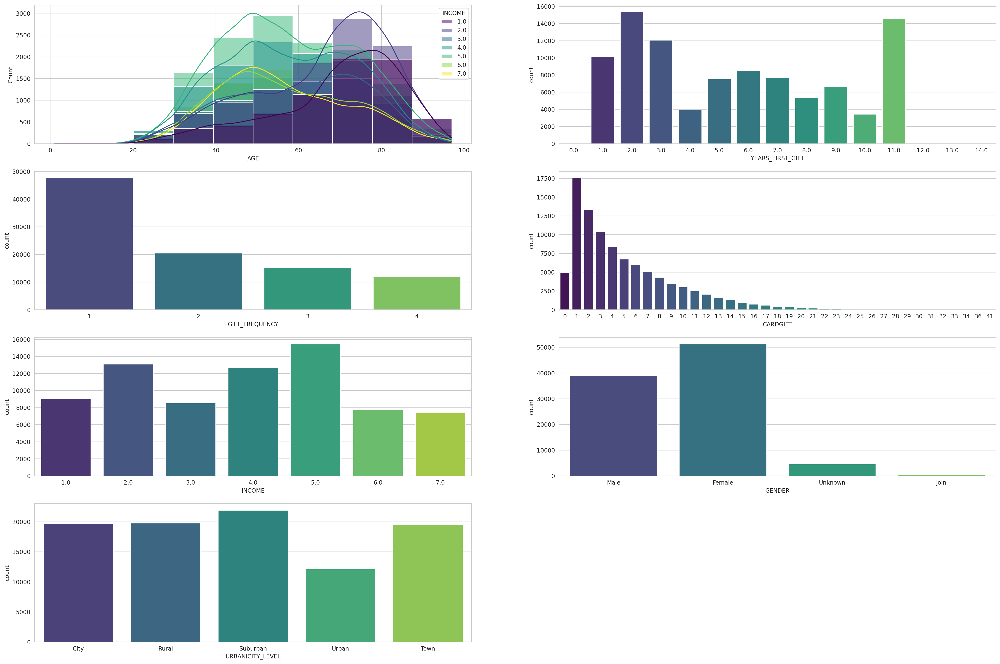

In [22]:
#Create a grid to visualize Age, Years_first_gift, Gift_frecuency, Cardgift, Income, Gender and Urbanicity level
f = plt.figure(figsize = (30,20))
gs = f.add_gridspec(4, 2)

with sns.axes_style("whitegrid"):
    
    ax = f.add_subplot(gs[0, 0])
    sns.histplot(x = 'AGE', data = pva, bins = 10, ax = ax, kde = True, hue = 'INCOME', palette = 'viridis')

    ax = f.add_subplot(gs[0, 1])
    sns.countplot(x = 'YEARS_FIRST_GIFT', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[1, 0])
    sns.countplot(x = 'GIFT_FREQUENCY', data = pva, ax = ax, palette = 'viridis')

    ax = f.add_subplot(gs[1, 1])
    sns.countplot(x = 'CARDGIFT', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[2, 0])
    sns.countplot(x = 'INCOME', data = pva, ax = ax, palette = 'viridis')  
    
    ax = f.add_subplot(gs[2, 1])
    sns.countplot(x = 'GENDER', data = pva, ax = ax, palette = 'viridis') 
    
    ax = f.add_subplot(gs[3, 0])
    sns.countplot(x = 'URBANICITY_LEVEL', data = pva, ax = ax, palette = 'viridis') 


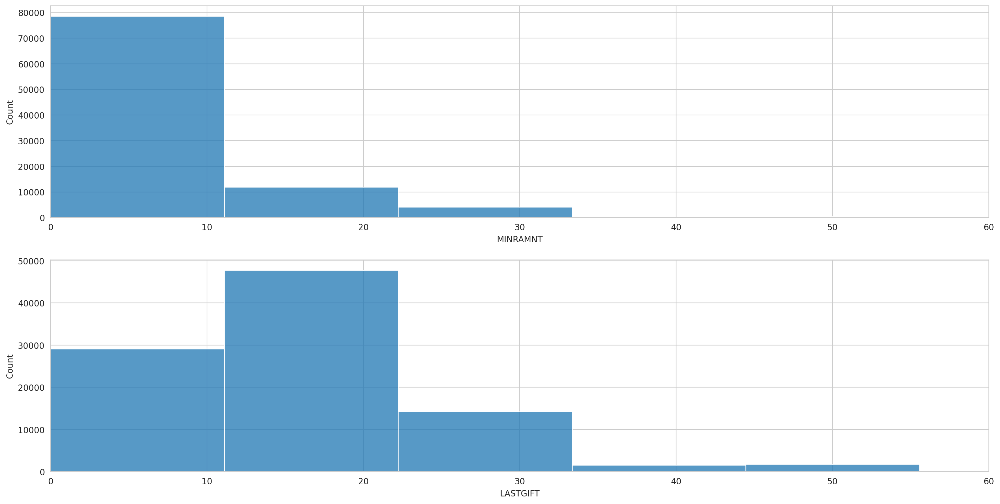

In [23]:
#create a grid to plot Minramnt and Lastgift
f = plt.figure(figsize = (20,10))
gs = f.add_gridspec(2, 1)

with sns.axes_style("whitegrid"):
    
    ax = f.add_subplot(gs[0, 0])
    sns.histplot(x = 'MINRAMNT', bins = 90, data = pva, ax = ax, palette = 'viridis')
    plt.xlim([0, 60])
        
    ax = f.add_subplot(gs[1, 0])
    sns.histplot(x = 'LASTGIFT', bins = 90, data = pva, ax = ax, palette = 'viridis') 
    plt.xlim([0, 60])

(0.0, 10.0)

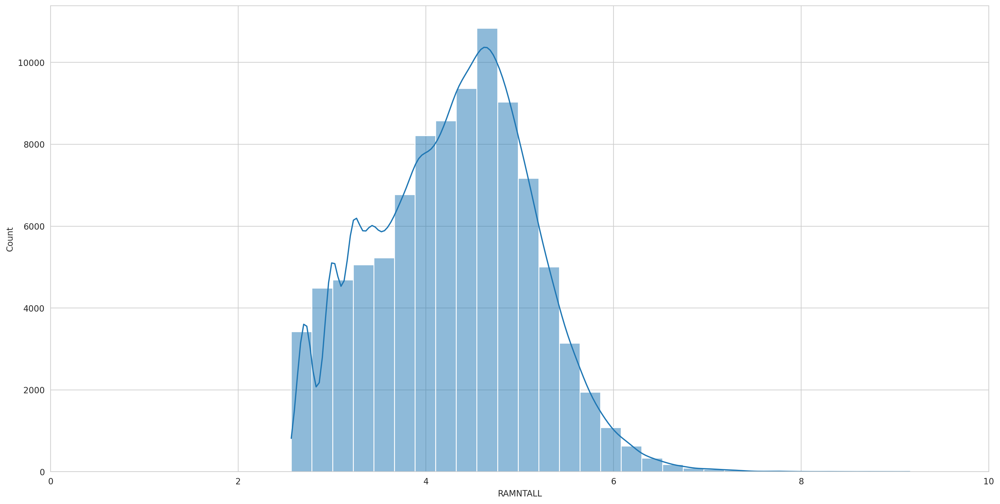

In [24]:
#visualize log_ramntall
a4_dims = (20, 10)
fig, ax = pyplot.subplots(figsize = a4_dims)

sns.histplot(x = np.log(pva['RAMNTALL']), bins = 30,  ax = ax, palette = 'viridis', kde=True) ## data = pva,
plt.xlim([0, 10])

(0.0, 10.0)

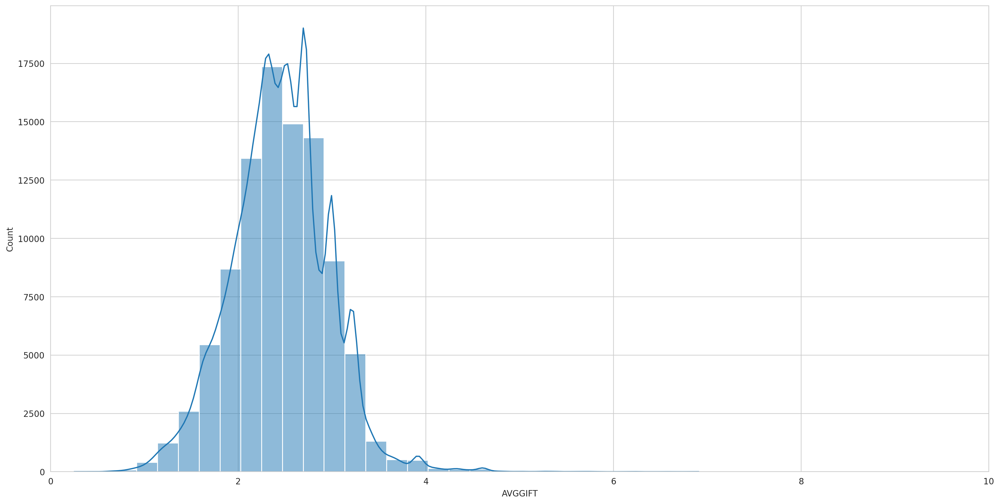

In [25]:
#visualize Log_avggift
a4_dims = (20, 10)
fig, ax = pyplot.subplots(figsize = a4_dims)

sns.histplot(x = np.log(pva['AVGGIFT']), bins = 30,  ax = ax, palette = 'viridis', kde=True) ## data = pva,
plt.xlim([0, 10])

(0.0, 10.0)

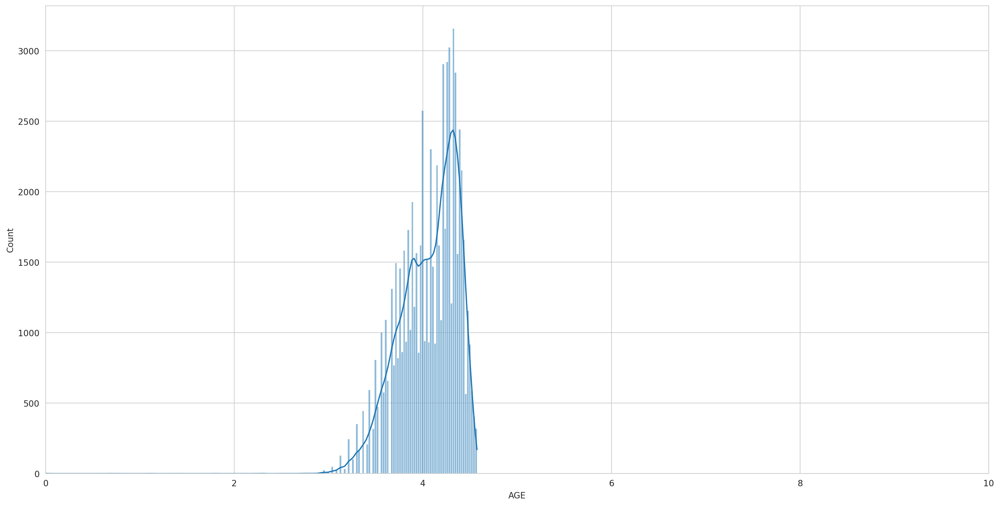

In [26]:
#visualize Log_age
a4_dims = (20, 10)
fig, ax = pyplot.subplots(figsize = a4_dims)

sns.histplot(x = np.log(pva['AGE']),  ax = ax, palette = 'viridis', kde=True) ## data = pva,
plt.xlim([0, 10])

(0.0, 50.0)

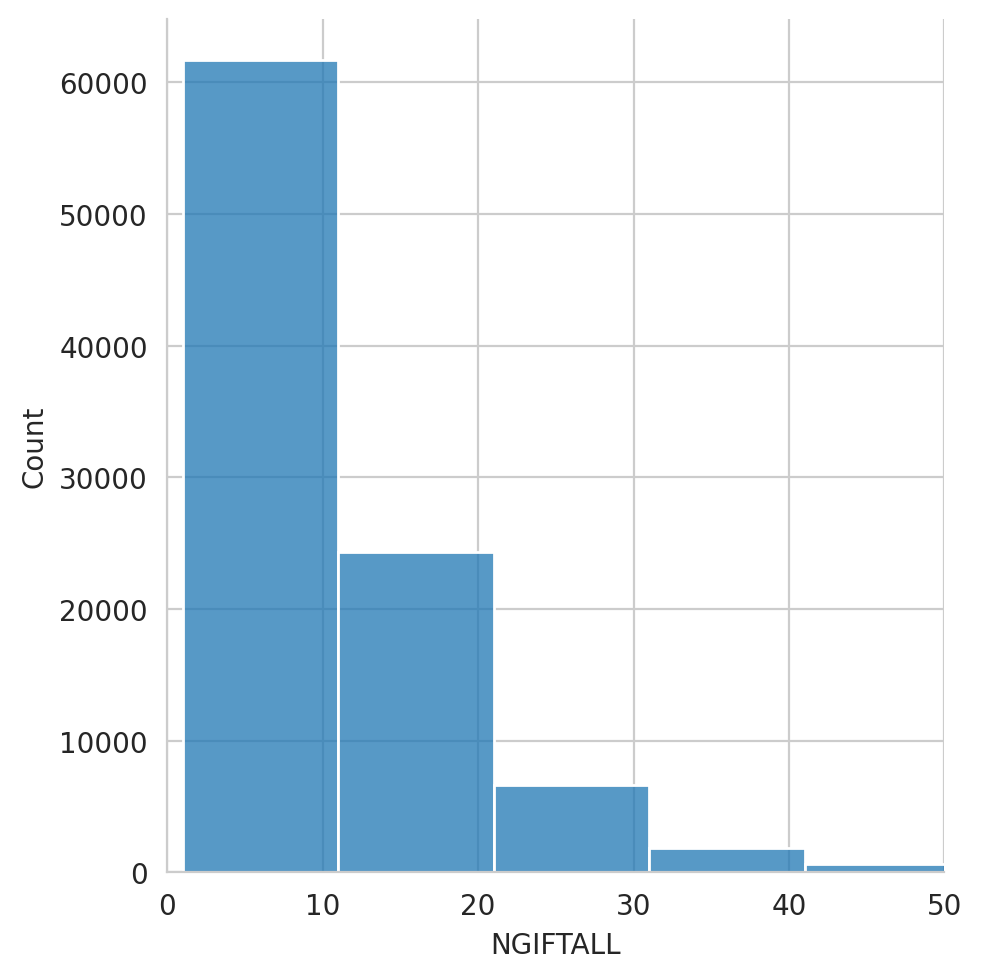

In [27]:
#visualize Nigiftall
sns.displot(x = 'NGIFTALL', data = pva, binwidth= 10, palette='viridis')
plt.xlim([0, 50])

(0.0, 40.0)

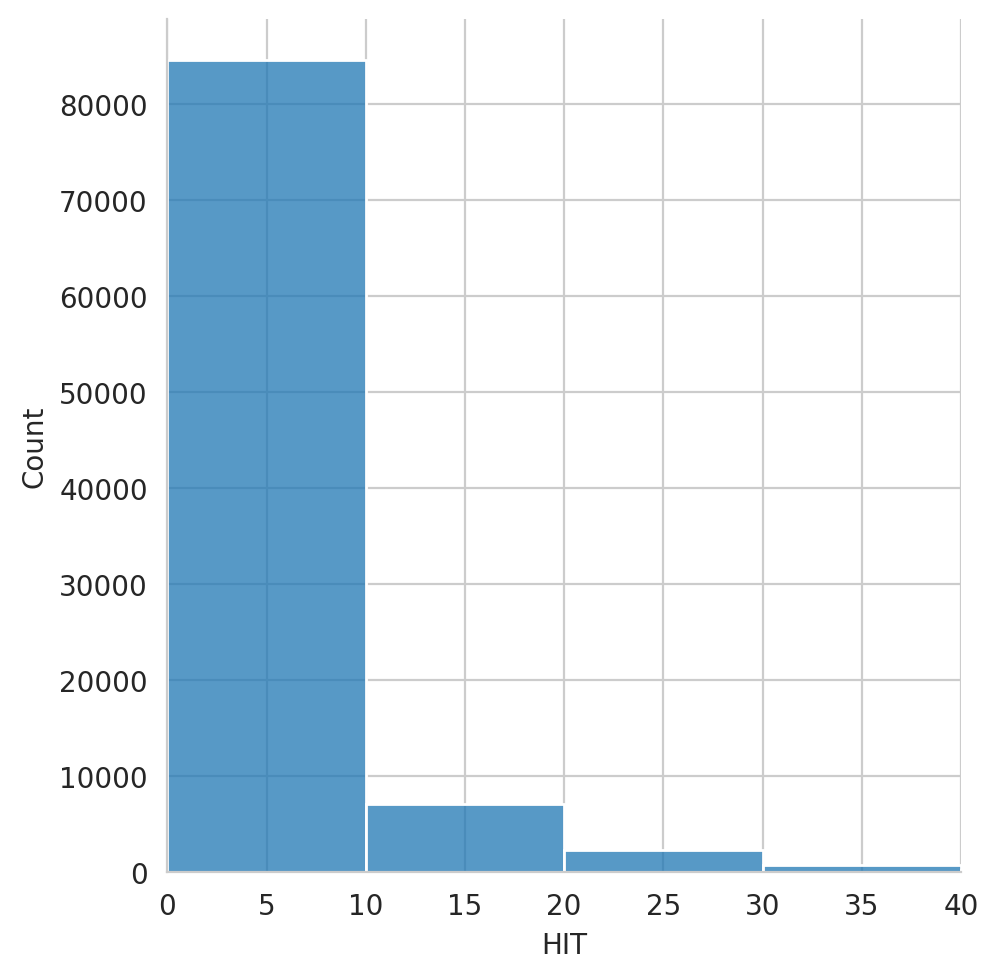

In [28]:
#visualize Hit
sns.displot(x = 'HIT', data = pva, palette = 'viridis', binwidth= 10)
plt.xlim([0, 40])

<AxesSubplot:xlabel='STATE', ylabel='count'>

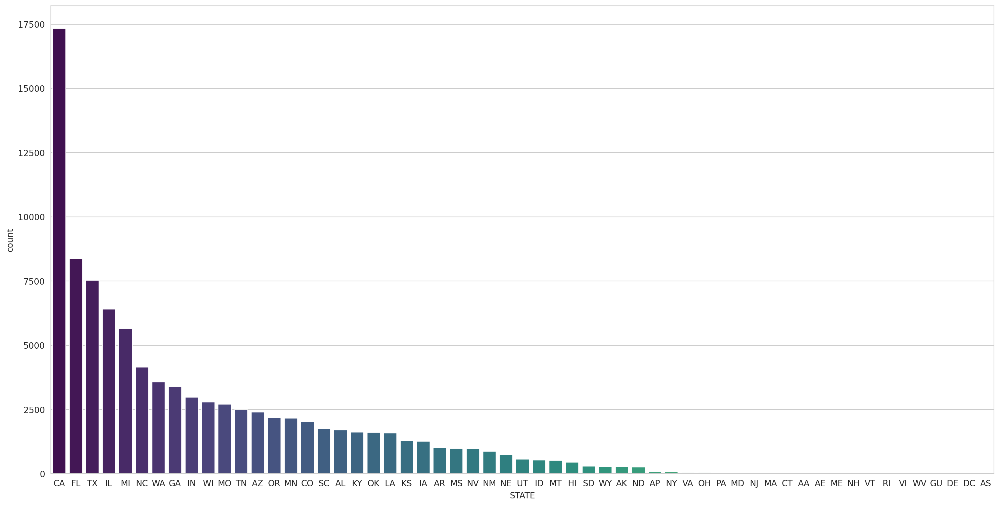

In [29]:
#visualice donnor by state ordered in descending manner
a4_dims = (20, 10)
fig, ax = pyplot.subplots(figsize = a4_dims)
sns.countplot(x = 'STATE', data = pva, ax = ax, palette = 'viridis', 
                 order = pva['STATE'].value_counts().index)

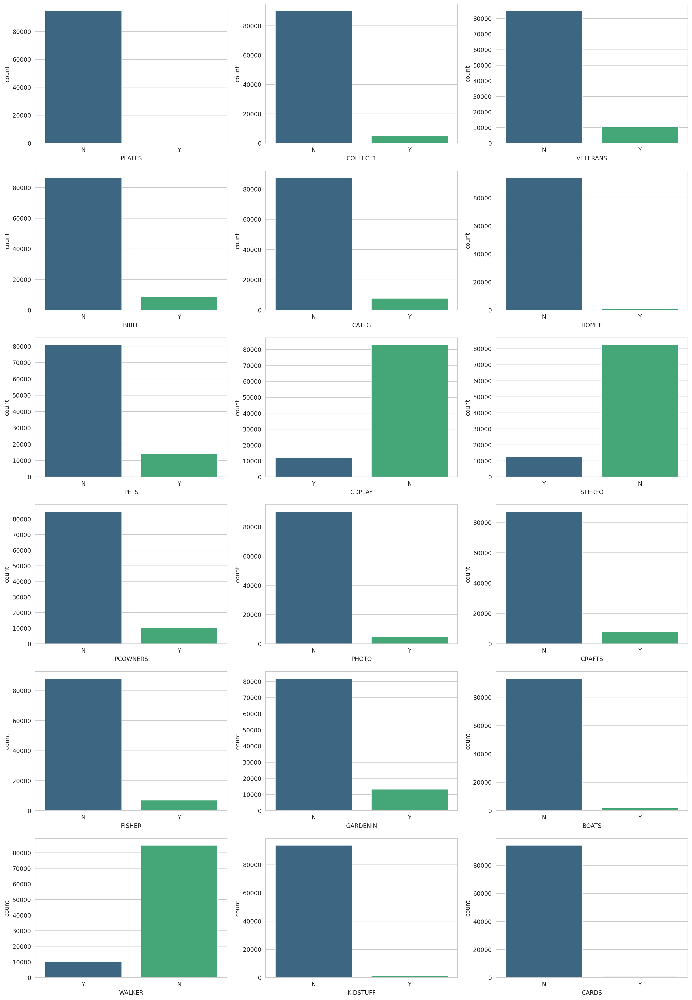

In [30]:
#visualize nterests
f = plt.figure(figsize = (20,30))
gs = f.add_gridspec(6, 3)

with sns.axes_style("whitegrid"):
    
    ax = f.add_subplot(gs[0, 0])
    sns.countplot(x = 'PLATES', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[0, 1])
    sns.countplot(x = 'COLLECT1', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[0, 2])
    sns.countplot(x = 'VETERANS', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[1, 0])
    sns.countplot(x = 'BIBLE', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[1, 1])
    sns.countplot(x = 'CATLG', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[1, 2])
    sns.countplot(x = 'HOMEE', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[2, 0])
    sns.countplot(x = 'PETS', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[2, 1])
    sns.countplot(x = 'CDPLAY', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[2, 2])
    sns.countplot(x = 'STEREO', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[3, 0])
    sns.countplot(x = 'PCOWNERS', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[3, 1])
    sns.countplot(x = 'PHOTO', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[3, 2])
    sns.countplot(x = 'CRAFTS', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[4, 0])
    sns.countplot(x = 'FISHER', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[4, 1])
    sns.countplot(x = 'GARDENIN', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[4, 2])
    sns.countplot(x = 'BOATS', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[5, 0])
    sns.countplot(x = 'WALKER', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[5, 1])
    sns.countplot(x = 'KIDSTUFF', data = pva, ax = ax, palette = 'viridis')
    
    ax = f.add_subplot(gs[5, 2])
    sns.countplot(x = 'CARDS', data = pva, ax = ax, palette = 'viridis')
    
    

# Filling Missing Values

In [31]:
# Use KNNImputer to fill missing values on numeric features
imputer = KNNImputer(n_neighbors=5, weights = 'uniform')
pva_metric[['LOG_AGE', 'INCOME']] = imputer.fit_transform(pva_metric[['LOG_AGE', 'INCOME']])

In [32]:
#create a list with categorical features with missing values
mode_as_missing_value = ['URBANICITY_LEVEL']

In [33]:
#fill missing values in non metric features with mode
for missing_feature in mode_as_missing_value:
    pva_non_metric[missing_feature].fillna(pva_non_metric[missing_feature].mode()[0], inplace = True)

In [34]:
#fill nan values of Timelag with 0
pva_metric['TIMELAG'].fillna(0, inplace=True)

In [35]:
#check is missing values of categorical features were correctly filled
pva_non_metric.isna().any()

STATE               False
GENDER              False
URBANICITY_LEVEL    False
COLLECT1            False
VETERANS            False
BIBLE               False
CATLG               False
HOMEE               False
PETS                False
CDPLAY              False
STEREO              False
PCOWNERS            False
PHOTO               False
CRAFTS              False
FISHER              False
GARDENIN            False
BOATS               False
WALKER              False
KIDSTUFF            False
CARDS               False
PLATES              False
dtype: bool

In [36]:
#check is missing values of metric features were correctly filled
pva_metric.isna().any()

INCOME              False
LASTGIFT            False
MINRAMNT            False
LOG_RAMNTALL        False
LOG_AGE             False
LOG_AVGGIFT         False
YEARS_FIRST_GIFT    False
NGIFTALL            False
GIFT_FREQUENCY      False
TIMELAG             False
HIT                 False
CARDGIFT            False
dtype: bool

# Outlier Removal

In [37]:
#create an IQR with the 10th and 90th quantiles
q10 = pva_metric.quantile(.10)
q90 = pva_metric.quantile(.90)
iqr = (q90 - q10)

upper_lim = q90 + 1.5*iqr
lower_lim = q10 - 1.5*iqr

In [38]:
#create a filter with the observations out of the IQR
filters = []
for metric in pva_metric_list:
    llim = lower_lim[metric]
    ulim = upper_lim[metric]
    filters.append(pva_metric[metric].between(llim, ulim, inclusive=True))

filters = pd.Series(np.all(filters, 0), index = pva_metric.index.tolist())   

#print the percentage of data kept after applying the filter created above
print('Percentage of data kept after removing outliers:', np.round(pva_metric[filters].shape[0]/pva_metric.shape[0], 2))

#replace the metric data base for the filtered one
pva_metric = pva_metric[filters]

Percentage of data kept after removing outliers: 0.97


In [39]:
#replace the categorical data base for the filtered one
pva_non_metric = pva_non_metric[filters]

# Data Normalization

In [40]:
#create a copy of data base with missing values filled and outlier removed
pva_standard = pva_metric.copy()

In [41]:
#scaling data using standarscaler to get a mean of 0 and variance of 1
scaler = StandardScaler()
scaled_feat = scaler.fit_transform(pva_standard)

In [42]:
#create a data base with standarized metric features
pva_standard[pva_metric_list] = scaled_feat

In [43]:
pva_standard

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT
CONTROLN,,,,,,,,,,,,
1,0.064443,1.676374,0.388390,1.648644,1.262193,1.434455,0.418457,0.318430,1.013685,-0.674547,3.268237,0.224581
2,1.868490,-0.786700,-0.421625,0.961961,0.707470,-0.305767,0.418457,0.816730,-0.851190,-0.511250,-0.123714,-0.455332
4,0.665792,0.075376,-0.421625,1.317064,-1.515674,0.562618,0.418457,0.567580,-0.851190,-0.674547,1.871552,-0.002057
5,-1.138255,-0.170932,-0.421625,1.753231,1.533786,-0.606403,0.710553,3.183653,-0.851190,-1.164438,-0.522767,0.451218
8,-0.003962,-0.170932,-0.745631,0.061430,-0.000725,-0.834531,0.710553,0.069280,-0.851190,-1.164438,-0.522767,0.224581
...,...,...,...,...,...,...,...,...,...,...,...,...
191760,0.665792,-0.786700,-0.421625,1.179007,1.445394,0.485805,1.002649,0.443005,1.013685,2.754685,-0.522767,-0.002057
191762,0.665792,-0.170932,-0.421625,1.103757,0.246216,0.706056,0.126361,0.193855,0.081247,0.958421,-0.522767,0.224581
191775,1.267141,1.060605,-0.421625,2.241088,1.118754,0.987775,1.294745,1.813329,-0.851190,-0.021360,-0.522767,1.357768


# Correlation Matrix

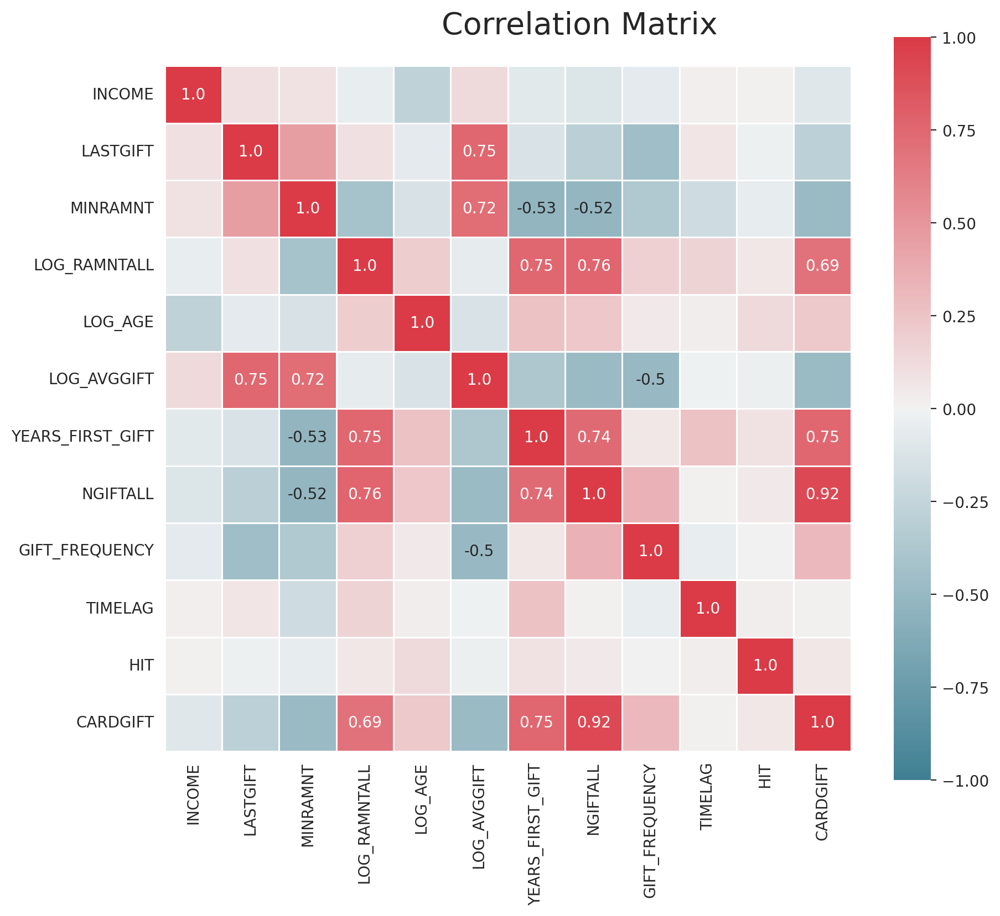

In [44]:
fig = plt.figure(figsize=(10, 8))

#obtain correlation matrix. Round the values to 2 decimal cases.
corr_matrix = np.round(pva_metric[pva_metric_list].corr(method='pearson'), decimals=2)

#build annotation matrix (values above |0.5| will appear annotated in the plot)
mask_annot = np.absolute(corr_matrix.values) >= 0.5
annot = np.where(mask_annot, corr_matrix.values, np.full(corr_matrix.shape,''))

#plot heatmap of the correlation matrix
sns.heatmap(data=corr_matrix, annot=annot, cmap=sns.diverging_palette(220, 10, as_cmap=True), 
            fmt='s', vmin=-1, vmax=1, center=0, square=True, linewidths=.5)

fig.subplots_adjust(top=0.95)
fig.suptitle("Correlation Matrix", fontsize=20)

plt.show()

# Assessing Clustering Tendency

## Visual Assesment Tendency

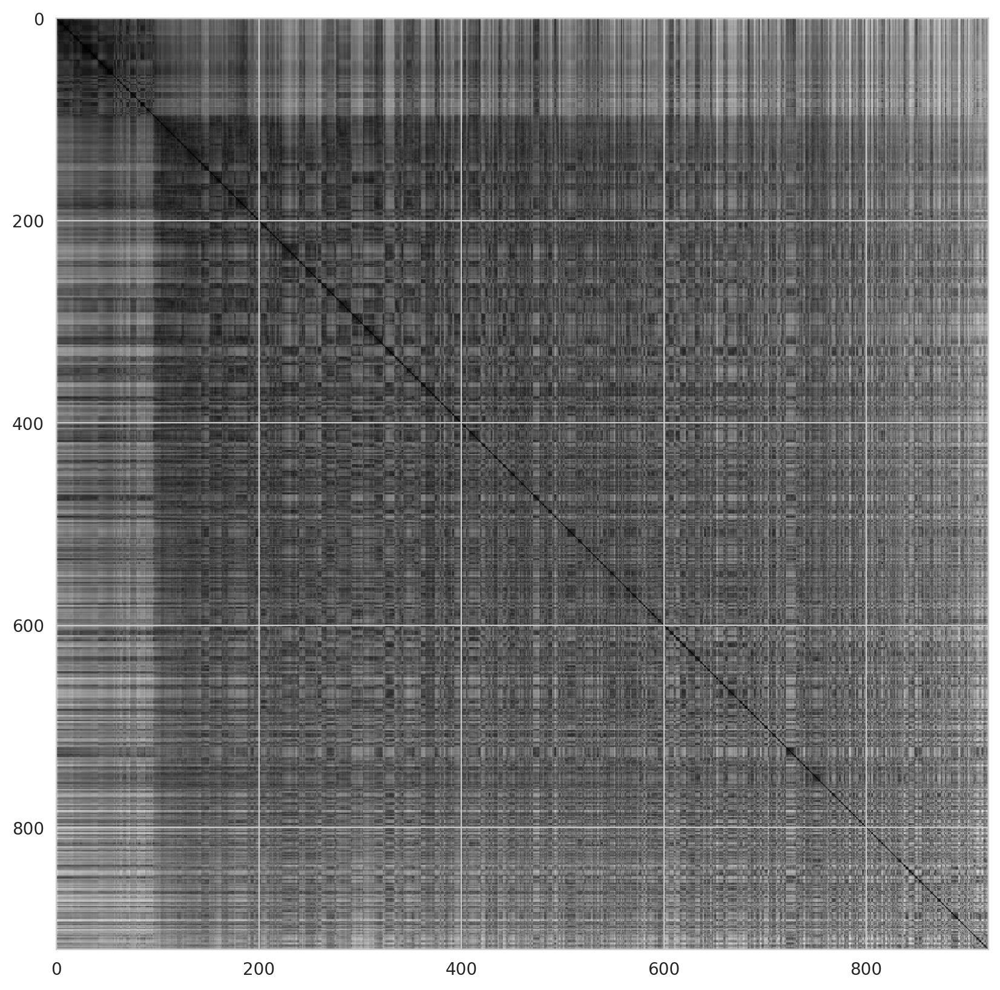

In [45]:
#apply vat algorithm to dataset 
vat(pva_standard.sample(frac = 0.01))

## Hopkins statistic

In [46]:
#apply Hopkins Statistic to data set
hopkins(pva_standard, len(pva_standard))

0.12119149261481423

# One Hot Encoding

In [47]:
#create a copy to encode categorial features
pva_non_metric_ohc = pva_non_metric.copy()

In [48]:
#apply the method OneHotEncoding
ohc = OneHotEncoder(sparse=False, drop= 'if_binary')
ohc_feat = ohc.fit_transform(pva_non_metric_ohc)
ohc_feat_names = ohc.get_feature_names(pva_non_metric_list)
ohc_pva = pd.DataFrame(ohc_feat, index = pva_non_metric_ohc.index, columns = ohc_feat_names)  
ohc_pva

,STATE_AA,STATE_AE,STATE_AK,STATE_AL,STATE_AP,STATE_AR,STATE_AS,STATE_AZ,STATE_CA,STATE_CO,...,PCOWNERS_Y,PHOTO_Y,CRAFTS_Y,FISHER_Y,GARDENIN_Y,BOATS_Y,WALKER_Y,KIDSTUFF_Y,CARDS_Y,PLATES_Y
CONTROLN,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191760,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
191762,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
191775,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Dimensionality Reduction

In [49]:
#create a copy to do PCA
pva_pca = pva_standard.copy()

In [50]:
#apply PCA to all metric features 
pca = PCA(n_components = pva_pca.shape[1], whiten = True)
pca_reduced = pca.fit_transform(pva_pca)

In [51]:
#The following table show the cumulative variance explained by the PC
pd.DataFrame(
    {"Eigenvalue": pca.explained_variance_,
     "Difference": np.insert(np.diff(pca.explained_variance_), 0, 0),
     "Proportion": pca.explained_variance_ratio_,
     "Cumulative": np.cumsum(pca.explained_variance_ratio_)},
    index=range(1, pca.n_components_ + 1)
)

,Eigenvalue,Difference,Proportion,Cumulative
1,4.435377,0.000000,0.369611,0.369611
2,1.927884,-2.507494,0.160655,0.530266
3,1.209743,-0.718141,0.100811,0.631077
4,1.076729,-0.133014,0.089726,0.720803
5,0.995988,-0.080741,0.082998,0.803801
6,0.690718,-0.305270,0.057559,0.861360
7,0.671097,-0.019621,0.055924,0.917285
8,0.440975,-0.230122,0.036748,0.954032
9,0.238114,-0.202861,0.019843,0.973875
10,0.181990,-0.056124,0.015166,0.989040


In [52]:
#check the number of components have a acumulated variance bigger that 90%
np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.9)

6

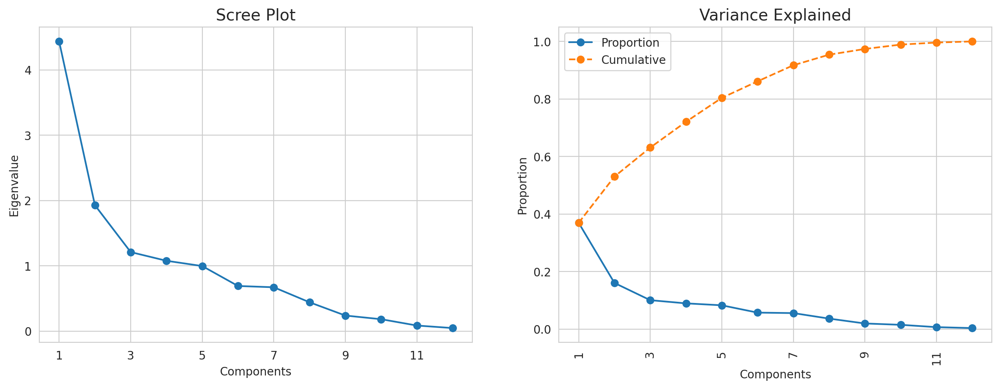

In [53]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# draw plots
ax1.plot(pca.explained_variance_, marker=".", markersize=12)
ax2.plot(pca.explained_variance_ratio_, marker=".", markersize=12, label="Proportion")
ax2.plot(np.cumsum(pca.explained_variance_ratio_), marker=".", markersize=12, linestyle="--", label="Cumulative")

# customizations
ax2.legend()
ax1.set_title("Scree Plot", fontsize=14)
ax2.set_title("Variance Explained", fontsize=14)
ax1.set_ylabel("Eigenvalue")
ax2.set_ylabel("Proportion")
ax1.set_xlabel("Components")
ax2.set_xlabel("Components")
ax1.set_xticks(range(0, pca.n_components_, 2))
ax1.set_xticklabels(range(1, pca.n_components_ + 1, 2))
ax2.set_xticks(range(0, pca.n_components_, 2))
ax2.set_xticklabels(range(1, pca.n_components_ + 1, 2))
plt.xticks(rotation = 90)

plt.show()

In [54]:
#create a list with the PC that explain 90% of the variance
pca_feat_names = [f"PC{i}" for i in range(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.9))]

In [55]:
#create a dataframe with the PC that explain 90% of the variance
pca_90_pct = pd.DataFrame(pca_reduced[:,0:6], index= pva_pca.index, columns = pca_feat_names) 

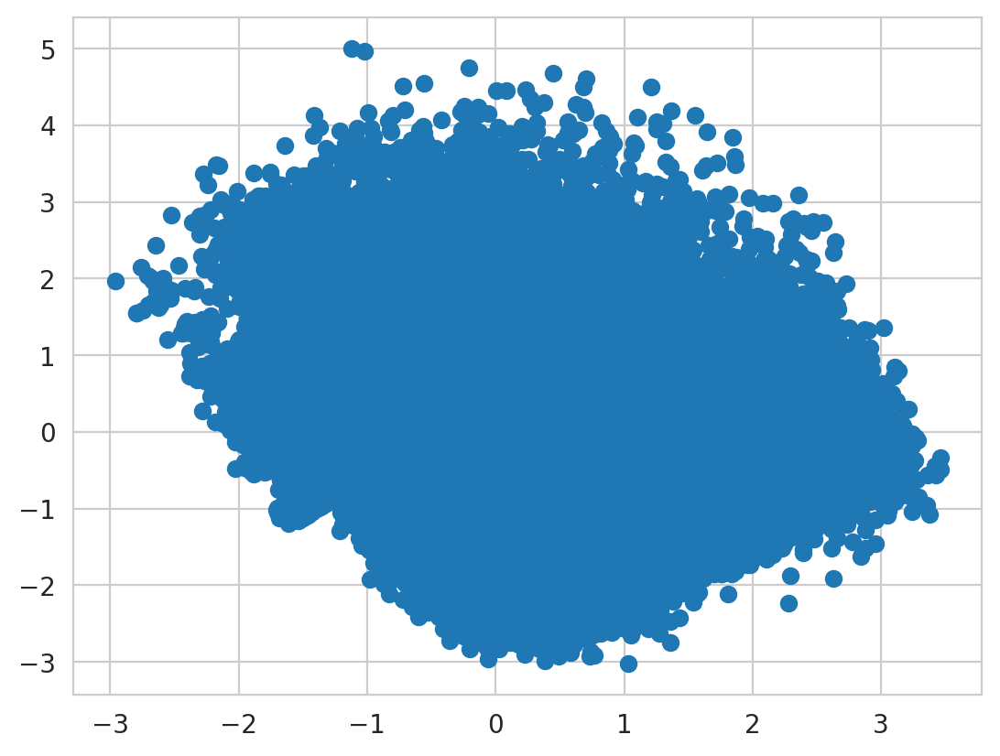

In [56]:
#plot data with the PC
plt.scatter(pca_90_pct['PC0'], pca_90_pct['PC1'])

# K-Means Clustering

## Define Number of Clusters

### Elbow Method

In [57]:
range_clusters = range(2,11)

In [58]:
#iterate over a desired ncluster range and save the inertia of the given cluster solution
inertia = []
for k in range_clusters: 
    kmclust = KMeans(n_clusters = k, init = 'k-means++', n_init = 15, random_state = 42)
    kmclust.fit(pva_standard)
    inertia.append(kmclust.inertia_)  

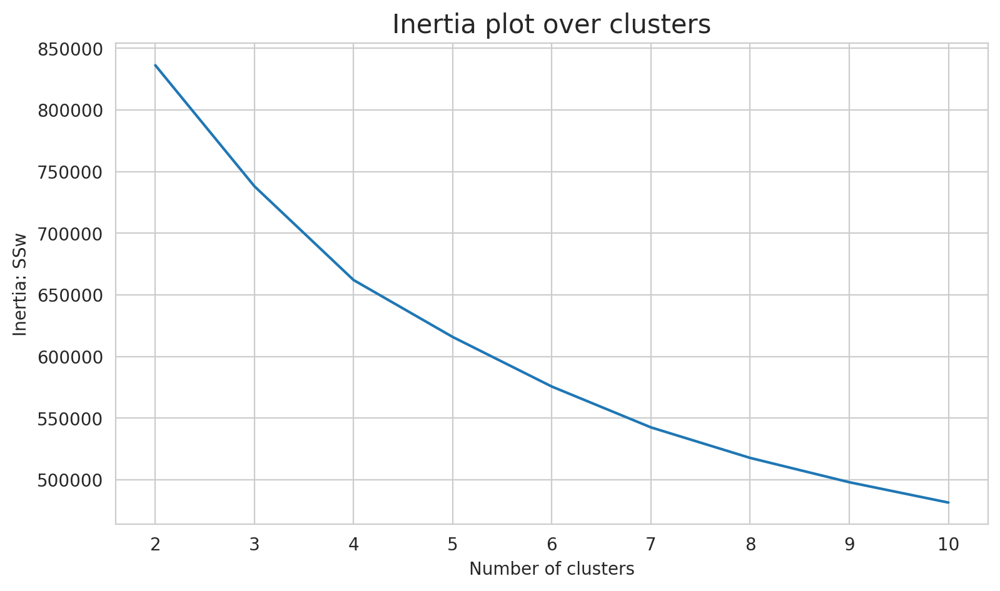

In [59]:
#plot inertia vs number of clusters
plt.figure(figsize=(9,5))
plt.plot(range_clusters , inertia) # range_clusters ,
plt.ylabel("Inertia: SSw")
plt.xlabel("Number of clusters")
plt.title("Inertia plot over clusters", size=15)
plt.show()

### Calinski-Harabasz Index

In [60]:
Calinski_Harabasz = []
for k in range_clusters:
    kmeans_model = KMeans(n_clusters = k, init = 'k-means++', n_init = 15,random_state = 42).fit(pva_standard)
    labels = kmeans_model.labels_
    labels = kmeans_model.labels_ 
    Calinski_Harabasz.append(metrics.calinski_harabasz_score(pva_standard, labels))

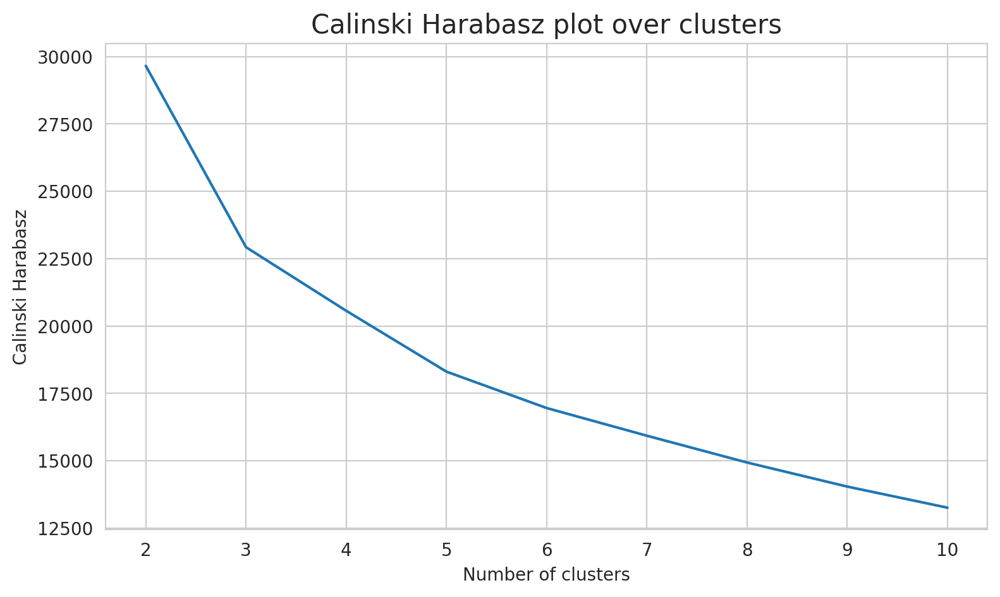

In [61]:
# The Calinski_Harabasz plot
plt.figure(figsize=(9,5))
plt.plot(range_clusters , Calinski_Harabasz) 
plt.ylabel("Calinski Harabasz")
plt.xlabel("Number of clusters")
plt.title("Calinski Harabasz plot over clusters", size=15)
plt.show()

## K-Means Clustering Solution

In [62]:
km_clust = KMeans(n_clusters = 4, init = 'k-means++', n_init = 15, random_state = 42)
km_labels = km_clust.fit_predict(pva_standard)

## Characterizing K-Means

### Metric Features

In [63]:
pva_standard_km_labeled = pd.concat((pva_standard, pd.Series(km_labels, name='labels', index=pva_standard.index.tolist())), axis=1)
km_standard = pva_standard_km_labeled.groupby('labels').mean()
km_standard['label'] = km_standard.index
km_standard

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT,label
labels,,,,,,,,,,,,,
0,0.131108,0.540211,-0.158631,0.164655,-0.050637,0.363979,0.102611,-0.306428,-0.534993,0.514879,0.029185,-0.326158,0
1,0.139219,0.550368,1.651967,-1.140305,-0.324021,1.053512,-1.137628,-0.955376,-0.667310,-0.642493,-0.130978,-0.891420,1
2,-0.252181,-0.544158,-0.646992,0.917509,0.460174,-0.737278,1.172328,1.337580,0.317619,-0.048670,0.124738,1.355830,2
3,-0.047659,-0.786747,-0.469071,-0.355111,-0.177278,-0.710829,-0.564320,-0.224181,1.167315,-0.238484,-0.082685,-0.272138,3


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 [Text(0, 0, 'INCOME'),
  Text(1, 0, 'LASTGIFT'),
  Text(2, 0, 'MINRAMNT'),
  Text(3, 0, 'LOG_RAMNTALL'),
  Text(4, 0, 'LOG_AGE'),
  Text(5, 0, 'LOG_AVGGIFT'),
  Text(6, 0, 'YEARS_FIRST_GIFT'),
  Text(7, 0, 'NGIFTALL'),
  Text(8, 0, 'GIFT_FREQUENCY'),
  Text(9, 0, 'TIMELAG'),
  Text(10, 0, 'HIT'),
  Text(11, 0, 'CARDGIFT')])

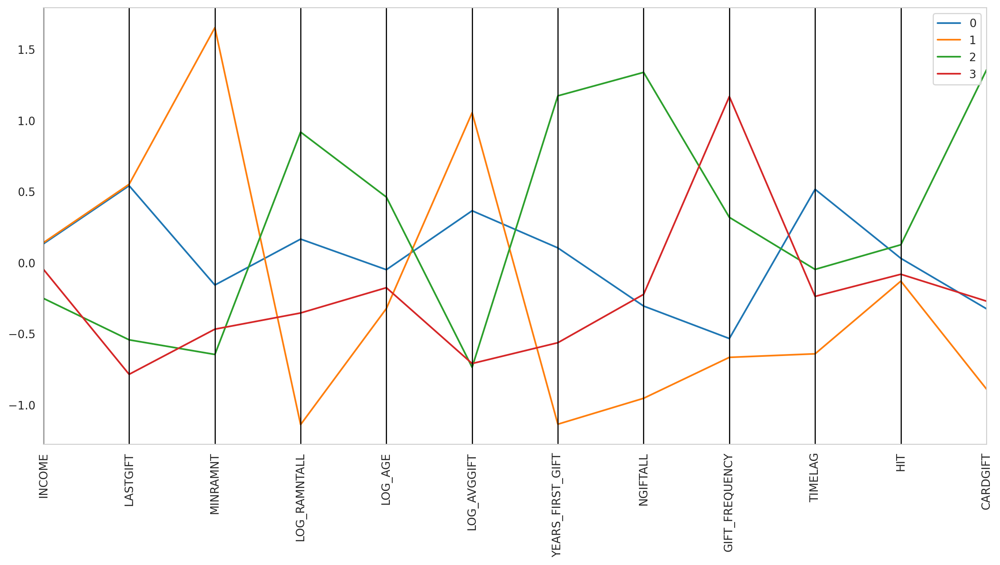

In [64]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_standard, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

In [65]:
pva_metric_km_labeled = pd.concat((pva_metric, pd.Series(km_labels, name='labels', index=pva_standard.index.tolist())), axis=1)
km_metric = pva_metric_km_labeled.groupby('labels').mean()
km_metric['label'] = km_metric.index
km_metric 

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT,label
labels,,,,,,,,,,,,,
0,4.110858,20.774428,6.623392,4.413896,4.049029,2.607291,5.918691,6.984080,1.339108,10.283833,2.766309,3.569958,0
1,4.124347,20.856904,17.799718,3.362555,3.977099,2.940486,1.672696,1.774779,1.197204,3.196291,1.963595,1.075835,1
2,3.473478,11.969430,3.608874,5.020433,4.183429,2.075143,9.580900,20.181021,2.253499,6.832757,3.245206,10.991448,2
3,3.813582,9.999622,4.707132,3.995146,4.015708,2.087923,3.635431,7.644300,3.164761,5.670371,2.205631,3.808313,3


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 [Text(0, 0, 'INCOME'),
  Text(1, 0, 'LASTGIFT'),
  Text(2, 0, 'MINRAMNT'),
  Text(3, 0, 'LOG_RAMNTALL'),
  Text(4, 0, 'LOG_AGE'),
  Text(5, 0, 'LOG_AVGGIFT'),
  Text(6, 0, 'YEARS_FIRST_GIFT'),
  Text(7, 0, 'NGIFTALL'),
  Text(8, 0, 'GIFT_FREQUENCY'),
  Text(9, 0, 'TIMELAG'),
  Text(10, 0, 'HIT'),
  Text(11, 0, 'CARDGIFT')])

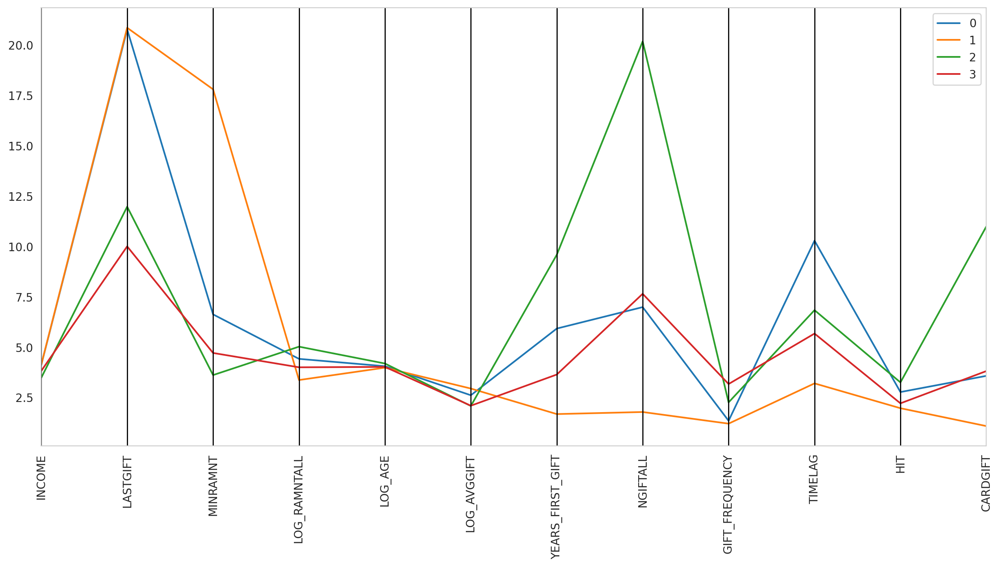

In [66]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_metric, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

### Categorical Features

In [67]:
pva_non_metric_km_labeled = pd.concat((ohc_pva, pd.Series(km_labels, name='labels', index=pva_standard.index.tolist())), axis=1)

#### State

In [68]:
km_state = pva_non_metric_km_labeled.groupby('labels').mean().iloc[:,:57]
km_state['label'] = km_state.index
km_state 

,STATE_AA,STATE_AE,STATE_AK,STATE_AL,STATE_AP,STATE_AR,STATE_AS,STATE_AZ,STATE_CA,STATE_CO,...,STATE_TX,STATE_UT,STATE_VA,STATE_VI,STATE_VT,STATE_WA,STATE_WI,STATE_WV,STATE_WY,label
labels,,,,,,,,,,,,,,,,,,,,,
0,0.000183,0.000153,0.003331,0.017172,0.000978,0.009289,0.000000,0.025270,0.192227,0.021481,...,0.079506,0.005836,0.000397,0.000061,0.000031,0.039631,0.028417,0.000031,0.003086,0
1,0.000228,0.000285,0.005763,0.017347,0.000970,0.010271,0.000057,0.023852,0.206619,0.022254,...,0.086448,0.006505,0.000970,0.000000,0.000171,0.036805,0.022710,0.000000,0.002967,1
2,0.000173,0.000000,0.000475,0.017709,0.000302,0.011964,0.000000,0.025527,0.156833,0.020560,...,0.069022,0.005270,0.000346,0.000000,0.000043,0.037059,0.035202,0.000130,0.003326,2
3,0.000160,0.000267,0.002725,0.020462,0.001336,0.012074,0.000000,0.025537,0.165295,0.020408,...,0.083182,0.006785,0.000801,0.000160,0.000107,0.034619,0.029864,0.000000,0.002404,3


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55, 56]),
 [Text(0, 0, 'STATE_AA'),
  Text(1, 0, 'STATE_AE'),
  Text(2, 0, 'STATE_AK'),
  Text(3, 0, 'STATE_AL'),
  Text(4, 0, 'STATE_AP'),
  Text(5, 0, 'STATE_AR'),
  Text(6, 0, 'STATE_AS'),
  Text(7, 0, 'STATE_AZ'),
  Text(8, 0, 'STATE_CA'),
  Text(9, 0, 'STATE_CO'),
  Text(10, 0, 'STATE_CT'),
  Text(11, 0, 'STATE_DC'),
  Text(12, 0, 'STATE_DE'),
  Text(13, 0, 'STATE_FL'),
  Text(14, 0, 'STATE_GA'),
  Text(15, 0, 'STATE_GU'),
  Text(16, 0, 'STATE_HI'),
  Text(17, 0, 'STATE_IA'),
  Text(18, 0, 'STATE_ID'),
  Text(19, 0, 'STATE_IL'),
  Text(20, 0, 'STATE_IN'),
  Text(21, 0, 'STATE_KS'),
  Text(22, 0, 'STATE_KY'),
  Text(23, 0, 'STATE_LA'),
  Text(24, 0, 'STATE_MA'),
  Text(25, 0, 'STATE_MD'),
  Text(26, 0, 'STATE_ME'),
  Text(27, 0, 'STAT

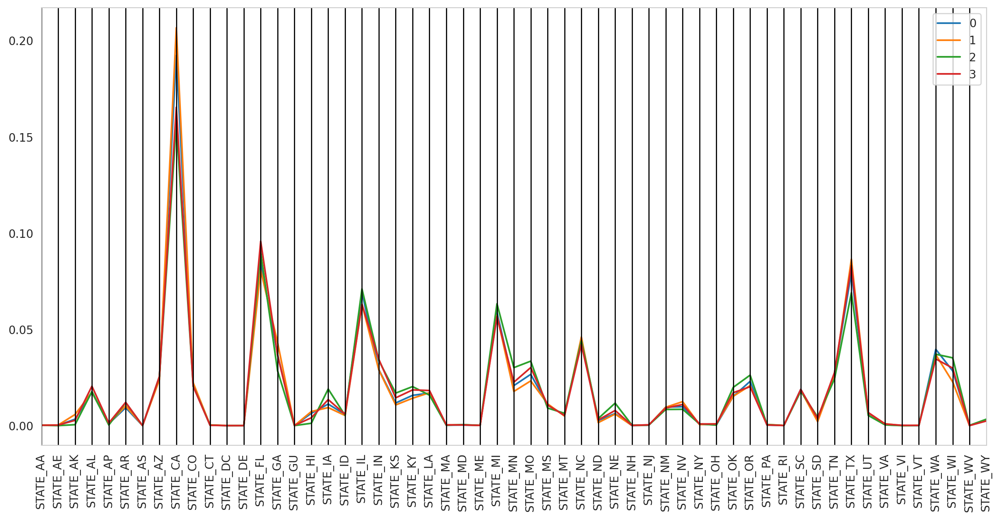

In [69]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_state, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

#### Gender

In [70]:
km_gender = pva_non_metric_km_labeled.groupby('labels').mean().iloc[:,57:61]
km_gender['label'] = km_gender.index
km_gender

,GENDER_Female,GENDER_Join,GENDER_Male,GENDER_Unknown,label
labels,,,,,
0,0.521374,0.003575,0.426376,0.048675,0
1,0.523252,0.001484,0.432582,0.042682,1
2,0.556194,0.005183,0.378326,0.060297,2
3,0.567903,0.004488,0.383588,0.044022,3


(array([0, 1, 2, 3]),
 [Text(0, 0, 'GENDER_Female'),
  Text(1, 0, 'GENDER_Join'),
  Text(2, 0, 'GENDER_Male'),
  Text(3, 0, 'GENDER_Unknown')])

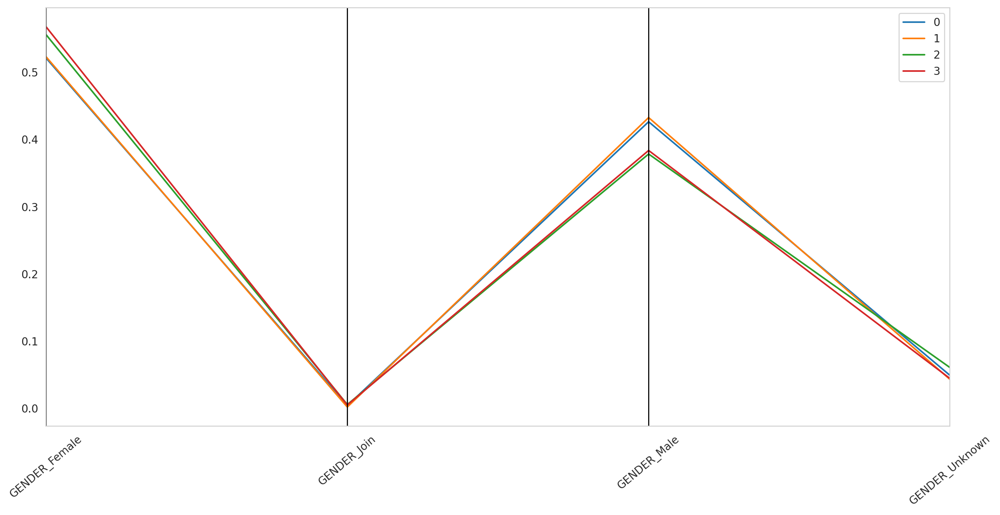

In [71]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_gender, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

#### Urbanicity Level

In [72]:
km_urbancity = pva_non_metric_km_labeled.groupby('labels').mean().iloc[:,61:66]
km_urbancity['label'] = km_urbancity.index
km_urbancity

,URBANICITY_LEVEL_City,URBANICITY_LEVEL_Rural,URBANICITY_LEVEL_Suburban,URBANICITY_LEVEL_Town,URBANICITY_LEVEL_Urban,label
labels,,,,,,
0,0.203654,0.199285,0.263911,0.202921,0.130229,0
1,0.199201,0.182882,0.274693,0.194408,0.148816,1
2,0.215748,0.240800,0.224128,0.207455,0.111869,2
3,0.200235,0.214232,0.246928,0.217919,0.120686,3


(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'URBANICITY_LEVEL_City'),
  Text(1, 0, 'URBANICITY_LEVEL_Rural'),
  Text(2, 0, 'URBANICITY_LEVEL_Suburban'),
  Text(3, 0, 'URBANICITY_LEVEL_Town'),
  Text(4, 0, 'URBANICITY_LEVEL_Urban')])

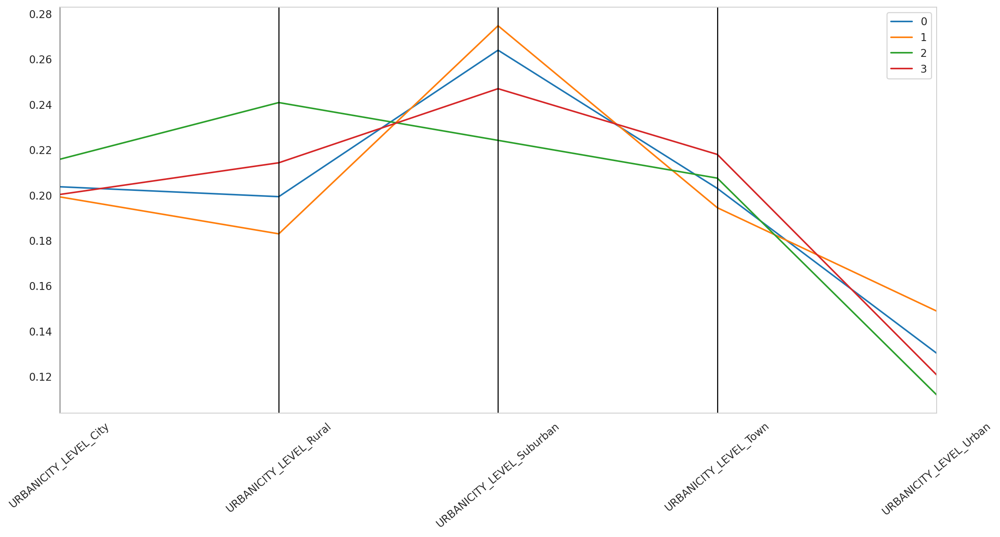

In [73]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_urbancity, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

#### Interests

In [74]:
km_interests = pva_non_metric_km_labeled.groupby('labels').mean().iloc[:,66:]
km_interests['label'] = km_interests.index
km_interests

,COLLECT1_Y,VETERANS_Y,BIBLE_Y,CATLG_Y,HOMEE_Y,PETS_Y,CDPLAY_Y,STEREO_Y,PCOWNERS_Y,PHOTO_Y,CRAFTS_Y,FISHER_Y,GARDENIN_Y,BOATS_Y,WALKER_Y,KIDSTUFF_Y,CARDS_Y,PLATES_Y,label
labels,,,,,,,,,,,,,,,,,,,
0,0.051914,0.104593,0.088612,0.081370,0.009381,0.150610,0.132612,0.132765,0.121154,0.050967,0.080362,0.072264,0.137043,0.022947,0.105693,0.015950,0.009411,0.004858,0
1,0.054836,0.095863,0.086790,0.079544,0.011641,0.156291,0.146990,0.142254,0.129073,0.051298,0.079144,0.075093,0.132953,0.024308,0.102254,0.016776,0.008902,0.006277,1
2,0.045525,0.116448,0.091439,0.074335,0.006738,0.128110,0.095629,0.112172,0.074076,0.042588,0.082282,0.065005,0.134934,0.014556,0.108760,0.011921,0.011144,0.005183,2
3,0.067315,0.113420,0.103270,0.091997,0.009723,0.168287,0.140453,0.151832,0.111230,0.055455,0.104391,0.092852,0.152687,0.023614,0.120900,0.019981,0.014157,0.007693,3


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17]),
 [Text(0, 0, 'COLLECT1_Y'),
  Text(1, 0, 'VETERANS_Y'),
  Text(2, 0, 'BIBLE_Y'),
  Text(3, 0, 'CATLG_Y'),
  Text(4, 0, 'HOMEE_Y'),
  Text(5, 0, 'PETS_Y'),
  Text(6, 0, 'CDPLAY_Y'),
  Text(7, 0, 'STEREO_Y'),
  Text(8, 0, 'PCOWNERS_Y'),
  Text(9, 0, 'PHOTO_Y'),
  Text(10, 0, 'CRAFTS_Y'),
  Text(11, 0, 'FISHER_Y'),
  Text(12, 0, 'GARDENIN_Y'),
  Text(13, 0, 'BOATS_Y'),
  Text(14, 0, 'WALKER_Y'),
  Text(15, 0, 'KIDSTUFF_Y'),
  Text(16, 0, 'CARDS_Y'),
  Text(17, 0, 'PLATES_Y')])

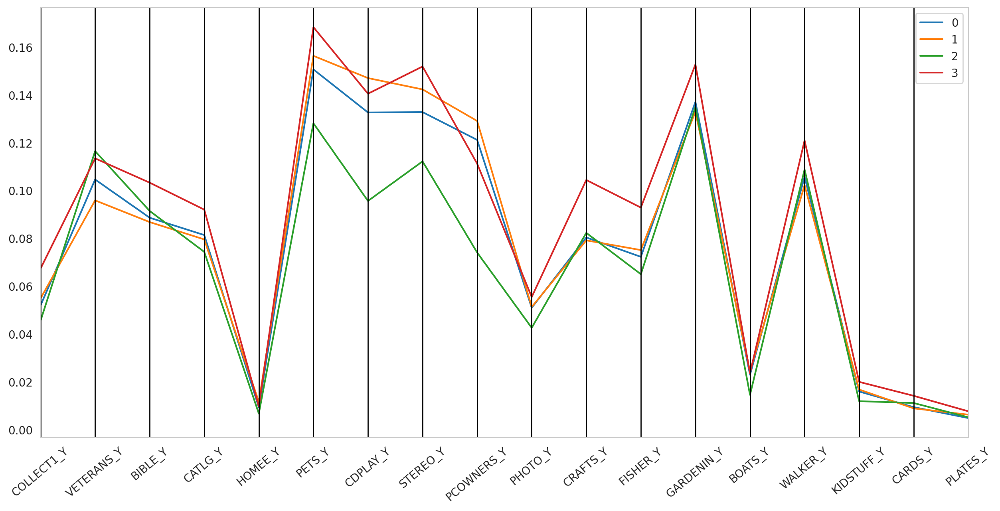

In [75]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(km_interests, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

## Visualization K-means

In [76]:
# t-SNE on a 5,000-donor sample, using the features only (not the cluster label).
tsne_sample = pva_standard_km_labeled.sample(5000, random_state=42)
two_dim_km = TSNE(random_state=42).fit_transform(tsne_sample.drop(columns="labels"))

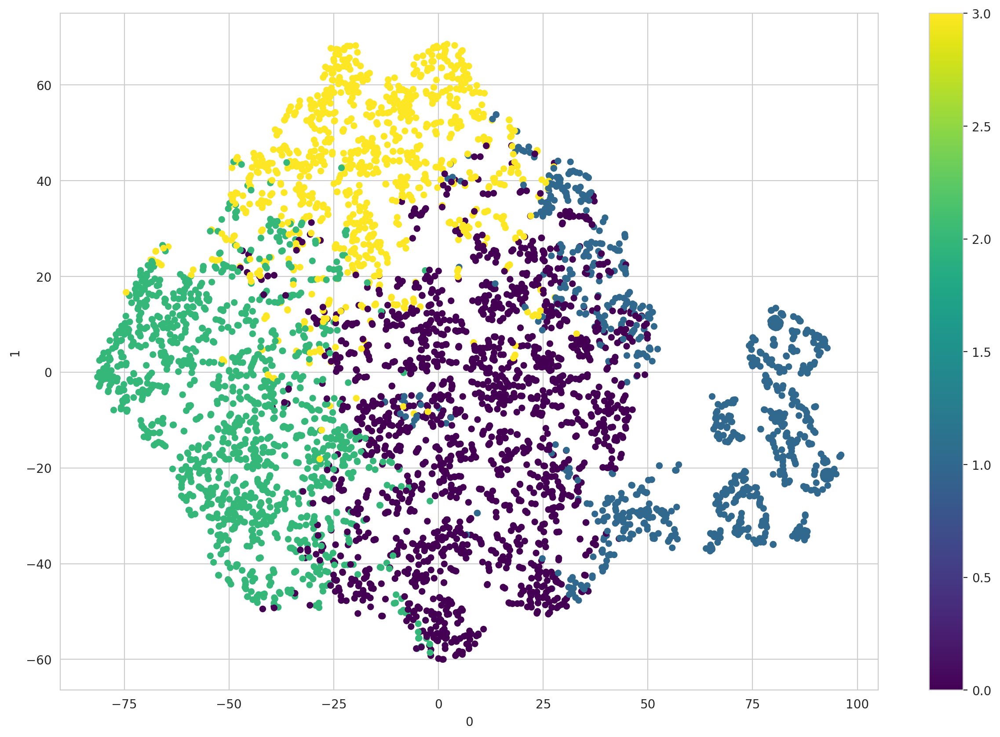

In [77]:
pd.DataFrame(two_dim_km).plot.scatter(x=0, y=1, c=tsne_sample['labels'], colormap='viridis', figsize=(15,10))
plt.show()

# Hierarchical and K-means Clustering

### Define large number of K-means clusters

In [78]:
km = KMeans(n_clusters = 30, init = 'k-means++', n_init = 10, random_state = 0)
km.fit(pva_standard)

KMeans(n_clusters=30, random_state=0)

In [79]:
km_labels_2 = km.predict(pva_standard)

In [80]:
km_labeled_2 = pd.concat((pva_standard, pd.Series(km_labels_2, name='Labels_km', index=pva_standard.index.tolist())), axis=1)
km_centroids_2 = km_labeled_2.groupby('Labels_km').mean()

In [81]:
km_labeled_metric_2 = pd.concat((pva_metric, pd.Series(km_labels_2, name='Labels_km', index=pva_metric.index.tolist())), axis=1)
km_centroids_metric_2 = km_labeled_metric_2.groupby('Labels_km').mean()

In [82]:
km_labeled_non_metric_2 = pd.concat((ohc_pva, pd.Series(km_labels_2, name='Labels_km', index=pva_standard.index.tolist())), axis=1)
km_centriods_non_metric_2  = km_labeled_non_metric_2.groupby('Labels_km').mean()

### Defining number of hierarquical clusters:

In [83]:
# setting distance_threshold=0 and n_clusters=None ensures we compute the full tree
linkage = 'ward'
distance = 'euclidean'
hclust_1 = AgglomerativeClustering(linkage=linkage, affinity=distance, n_clusters=None, distance_threshold=0.000001)
hclust_1.fit_predict(km_centroids_2)

array([26, 18, 17, 21, 15, 23, 24, 27, 28, 19,  8, 13, 20, 29, 22, 16, 14,
       25,  9,  6, 10, 11,  7,  3,  4, 12,  5,  2,  1,  0])

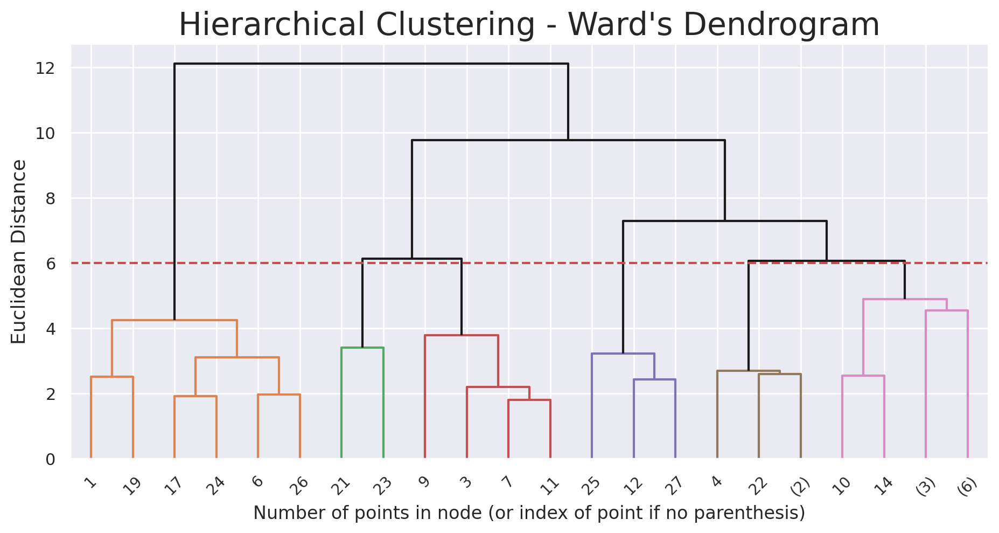

In [84]:
# Adapted from:
# create the counts of samples under each node (number of points being merged)
counts = np.zeros(hclust_1.children_.shape[0])
n_samples = len(hclust_1.labels_)

# hclust.children_ contains the observation ids that are being merged together
# At the i-th iteration, children[i][0] and children[i][1] are merged to form node n_samples + i
for i, merge in enumerate(hclust_1.children_):
    # track the number of observations in the current cluster being formed
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            # If this is True, then we are merging an observation
            current_count += 1  # leaf node
        else:
            # Otherwise, we are merging a previously formed cluster
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

# the hclust.children_ is used to indicate the two points/clusters being merged (dendrogram's u-joins)
# the hclust.distances_ indicates the distance between the two points/clusters (height of the u-joins)
# the counts indicate the number of points being merged (dendrogram's x-axis)
linkage_matrix = np.column_stack(
    [hclust_1.children_, hclust_1.distances_, counts]
).astype(float)

# Plot the corresponding dendrogram
sns.set()
fig = plt.figure(figsize=(11,5))
# The Dendrogram parameters need to be tuned
y_threshold = 6
dendrogram(linkage_matrix, truncate_mode='level', p=5, color_threshold=y_threshold, above_threshold_color='k')
plt.hlines(y_threshold, 0, 1000, colors="r", linestyles="dashed")
plt.title(f'Hierarchical Clustering - {linkage.title()}\'s Dendrogram', fontsize=21)
plt.xlabel('Number of points in node (or index of point if no parenthesis)')
plt.ylabel(f'{distance.title()} Distance', fontsize=13)
plt.show()

## Hierarchical on top of K-means

In [85]:
# # Performing Hierarchical Clustering
hc_km_cluster = AgglomerativeClustering(linkage='ward', affinity = 'euclidean', n_clusters = 5)
hc_km_labels = hc_km_cluster.fit_predict(km_centroids_2)

## Characterizing Hierarchical on top of K-means

### Metric Features

In [86]:
hc_km_labeled_standard = pd.concat((km_centroids_2, pd.Series(hc_km_labels, name='Labels_hc')), axis=1)
hc_km_standard = hc_km_labeled_standard.groupby('Labels_hc').mean()
hc_km_standard['Label_hc'] = hc_km_standard.index
hc_km_standard 

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT,Label_hc
Labels_hc,,,,,,,,,,,,,
0,-0.006260,0.007726,-0.249210,0.042849,-0.201940,0.002795,-0.066774,-0.190291,0.079722,0.313763,-0.229175,-0.216177,0
1,-0.283518,-0.781307,-0.707321,0.869936,0.477858,-1.032353,1.137848,1.636964,0.660106,-0.160844,-0.173082,1.627219,1
2,0.221220,0.411692,1.835978,-1.466241,-0.234238,1.061938,-1.229893,-1.018693,-0.775278,-0.989914,0.417439,-0.941044,2
3,-0.005849,-0.132465,-0.389477,0.340423,0.444475,-0.196000,0.422226,0.223326,0.024787,0.116165,2.836123,0.233524,3
4,0.261139,2.623663,1.375816,0.679400,-0.121017,1.716868,-0.216058,-0.431038,-0.434995,0.372738,-0.200184,-0.438941,4


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 [Text(0, 0, 'INCOME'),
  Text(1, 0, 'LASTGIFT'),
  Text(2, 0, 'MINRAMNT'),
  Text(3, 0, 'LOG_RAMNTALL'),
  Text(4, 0, 'LOG_AGE'),
  Text(5, 0, 'LOG_AVGGIFT'),
  Text(6, 0, 'YEARS_FIRST_GIFT'),
  Text(7, 0, 'NGIFTALL'),
  Text(8, 0, 'GIFT_FREQUENCY'),
  Text(9, 0, 'TIMELAG'),
  Text(10, 0, 'HIT'),
  Text(11, 0, 'CARDGIFT')])

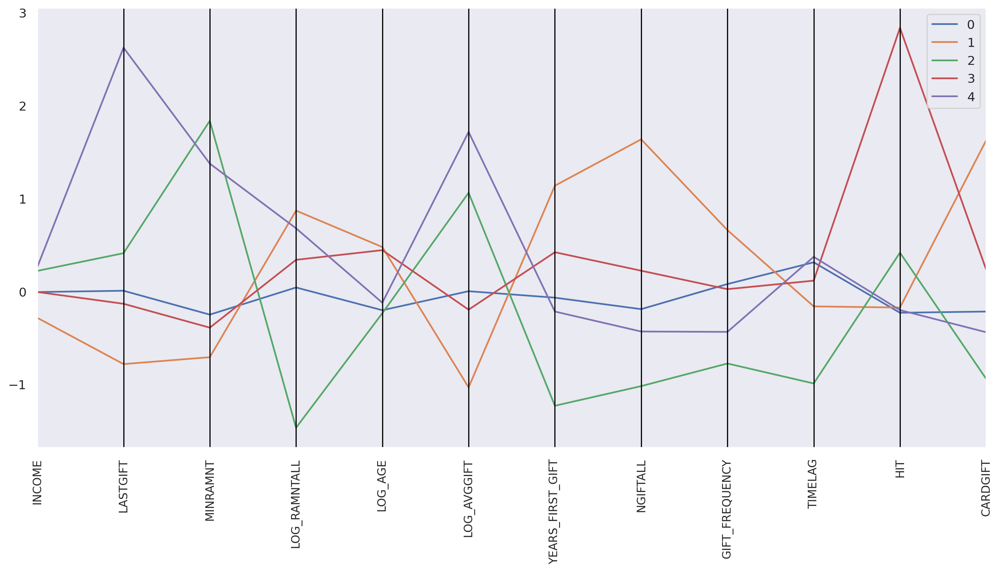

In [87]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_standard, class_column = 'Label_hc', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

In [88]:
hc_km_labeled_metric = pd.concat((km_centroids_metric_2, pd.Series(hc_km_labels, name='Labels_hc')), axis=1)
hc_km_metric = hc_km_labeled_metric.groupby('Labels_hc').mean()
hc_km_metric['Label_hc'] = hc_km_metric.index
hc_km_metric

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT,Label_hc
Labels_hc,,,,,,,,,,,,,
0,3.882426,16.450690,6.064270,4.315763,4.009220,2.432760,5.338796,7.916345,1.998364,9.052230,1.471444,4.055230,0
1,3.421366,10.043790,3.236476,4.982106,4.188082,1.932557,9.462858,22.584262,2.620801,6.145823,1.752575,12.188910,1
2,4.260709,19.730870,18.935568,3.099965,4.000722,2.944558,1.356823,1.266519,1.081413,1.068753,4.712187,0.856876,2
3,3.883109,15.312348,5.198442,4.555504,4.179298,2.336698,7.012904,11.236569,1.939449,7.842176,16.834301,6.039460,3
4,4.327092,37.691925,16.095114,4.828601,4.030511,3.261032,4.827717,5.983799,1.446352,9.413385,1.616742,3.072322,4


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 [Text(0, 0, 'INCOME'),
  Text(1, 0, 'LASTGIFT'),
  Text(2, 0, 'MINRAMNT'),
  Text(3, 0, 'LOG_RAMNTALL'),
  Text(4, 0, 'LOG_AGE'),
  Text(5, 0, 'LOG_AVGGIFT'),
  Text(6, 0, 'YEARS_FIRST_GIFT'),
  Text(7, 0, 'NGIFTALL'),
  Text(8, 0, 'GIFT_FREQUENCY'),
  Text(9, 0, 'TIMELAG'),
  Text(10, 0, 'HIT'),
  Text(11, 0, 'CARDGIFT')])

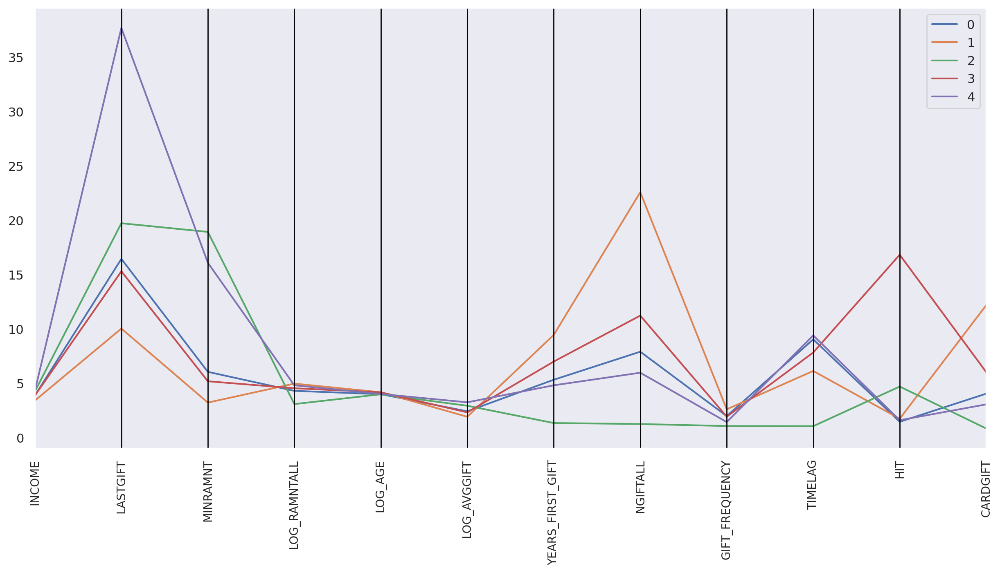

In [89]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_metric, class_column = 'Label_hc', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

### Categorical Features

In [90]:
hc_km_labeled_non_metric = pd.concat((km_centriods_non_metric_2, pd.Series(hc_km_labels, name='Labels_hc')), axis=1)

#### State

In [91]:
hc_km_state = hc_km_labeled_non_metric.groupby('Labels_hc', as_index=False).mean().iloc[:,1:57]
hc_km_state['label'] = hc_km_state.index
hc_km_state

,STATE_AA,STATE_AE,STATE_AK,STATE_AL,STATE_AP,STATE_AR,STATE_AS,STATE_AZ,STATE_CA,STATE_CO,...,STATE_TN,STATE_TX,STATE_UT,STATE_VA,STATE_VI,STATE_VT,STATE_WA,STATE_WI,STATE_WV,label
0,0.000160,0.000208,0.002915,0.018287,0.000981,0.010521,0.000000,0.025251,0.178554,0.021141,...,0.027642,0.080626,0.005983,0.000572,0.000076,0.000068,0.037931,0.029541,0.000012,0
1,0.000305,0.000047,0.000620,0.018661,0.000347,0.011917,0.000000,0.025080,0.150884,0.019495,...,0.024839,0.067336,0.005717,0.000293,0.000000,0.000088,0.036130,0.037763,0.000158,1
2,0.000231,0.000148,0.005403,0.016336,0.000751,0.010324,0.000062,0.024841,0.199399,0.023866,...,0.025525,0.090971,0.006417,0.000551,0.000000,0.000087,0.034760,0.023476,0.000000,2
3,0.000000,0.000161,0.000987,0.014390,0.000000,0.008008,0.000000,0.023660,0.167718,0.027521,...,0.021126,0.082836,0.005905,0.000335,0.000000,0.000000,0.037886,0.033417,0.000000,3
4,0.000313,0.000198,0.006811,0.012614,0.000593,0.009647,0.000000,0.028664,0.256195,0.019178,...,0.021932,0.079615,0.004139,0.001302,0.000000,0.000627,0.039692,0.021160,0.000000,4


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55]),
 [Text(0, 0, 'STATE_AA'),
  Text(1, 0, 'STATE_AE'),
  Text(2, 0, 'STATE_AK'),
  Text(3, 0, 'STATE_AL'),
  Text(4, 0, 'STATE_AP'),
  Text(5, 0, 'STATE_AR'),
  Text(6, 0, 'STATE_AS'),
  Text(7, 0, 'STATE_AZ'),
  Text(8, 0, 'STATE_CA'),
  Text(9, 0, 'STATE_CO'),
  Text(10, 0, 'STATE_CT'),
  Text(11, 0, 'STATE_DC'),
  Text(12, 0, 'STATE_DE'),
  Text(13, 0, 'STATE_FL'),
  Text(14, 0, 'STATE_GA'),
  Text(15, 0, 'STATE_GU'),
  Text(16, 0, 'STATE_HI'),
  Text(17, 0, 'STATE_IA'),
  Text(18, 0, 'STATE_ID'),
  Text(19, 0, 'STATE_IL'),
  Text(20, 0, 'STATE_IN'),
  Text(21, 0, 'STATE_KS'),
  Text(22, 0, 'STATE_KY'),
  Text(23, 0, 'STATE_LA'),
  Text(24, 0, 'STATE_MA'),
  Text(25, 0, 'STATE_MD'),
  Text(26, 0, 'STATE_ME'),
  Text(27, 0, 'STATE_MI

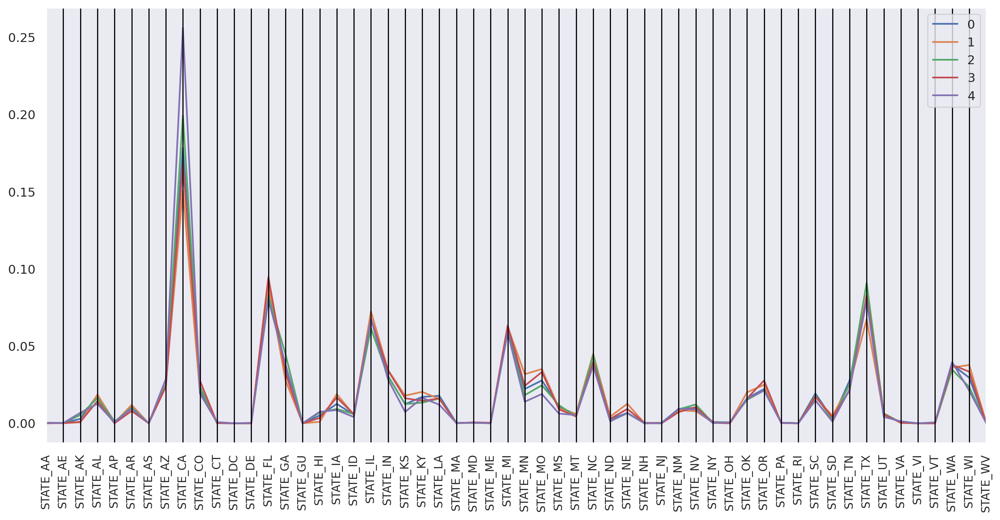

In [92]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_state, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=90)

#### Gender

In [93]:
hc_km_gender = hc_km_labeled_non_metric.groupby('Labels_hc', as_index=False).mean().iloc[:,57:61]
hc_km_gender['label'] = hc_km_gender.index
hc_km_gender

,STATE_WY,GENDER_Female,GENDER_Join,GENDER_Male,label
0,0.002741,0.542859,0.003846,0.405168,0
1,0.003335,0.571726,0.005941,0.359727,1
2,0.002748,0.514517,0.001200,0.447510,2
3,0.002950,0.531286,0.004916,0.448536,3
4,0.004090,0.492951,0.002985,0.449855,4


(array([0, 1, 2, 3]),
 [Text(0, 0, 'STATE_WY'),
  Text(1, 0, 'GENDER_Female'),
  Text(2, 0, 'GENDER_Join'),
  Text(3, 0, 'GENDER_Male')])

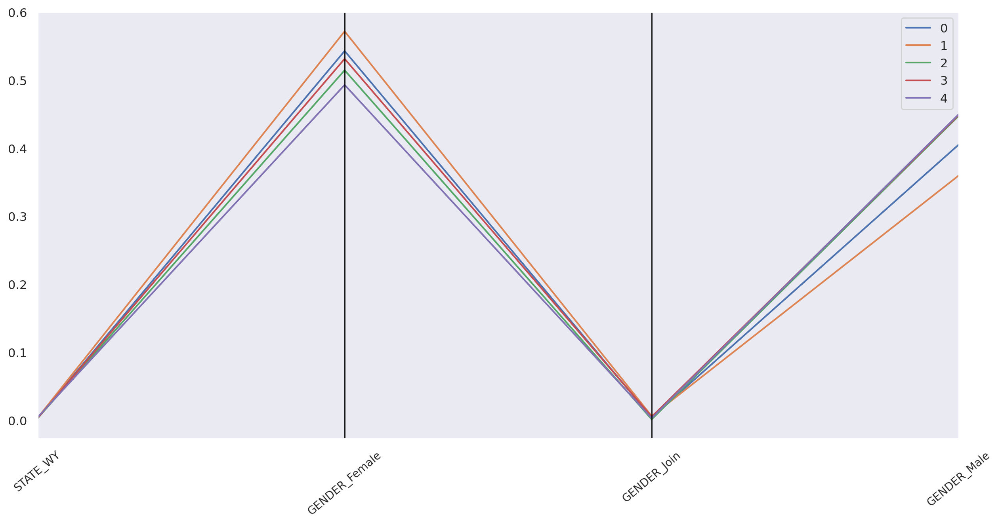

In [94]:
#plt.plot(hc_km_labeled_non_metric.iloc[:,61:66])
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_gender, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

#### Urbanicity Level

In [95]:
hc_km_urbanicity = hc_km_labeled_non_metric.groupby('Labels_hc', as_index=False).mean().iloc[:,61:66]
hc_km_urbanicity['label'] = hc_km_urbanicity.index
hc_km_urbanicity

,GENDER_Unknown,URBANICITY_LEVEL_City,URBANICITY_LEVEL_Rural,URBANICITY_LEVEL_Suburban,URBANICITY_LEVEL_Town,label
0,0.048128,0.199890,0.214110,0.253052,0.205994,0
1,0.062606,0.209648,0.256917,0.214496,0.210717,1
2,0.036773,0.200333,0.166908,0.282006,0.202787,2
3,0.015262,0.265294,0.132639,0.277427,0.207830,3
4,0.054209,0.193280,0.169560,0.295973,0.191212,4


(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'GENDER_Unknown'),
  Text(1, 0, 'URBANICITY_LEVEL_City'),
  Text(2, 0, 'URBANICITY_LEVEL_Rural'),
  Text(3, 0, 'URBANICITY_LEVEL_Suburban'),
  Text(4, 0, 'URBANICITY_LEVEL_Town')])

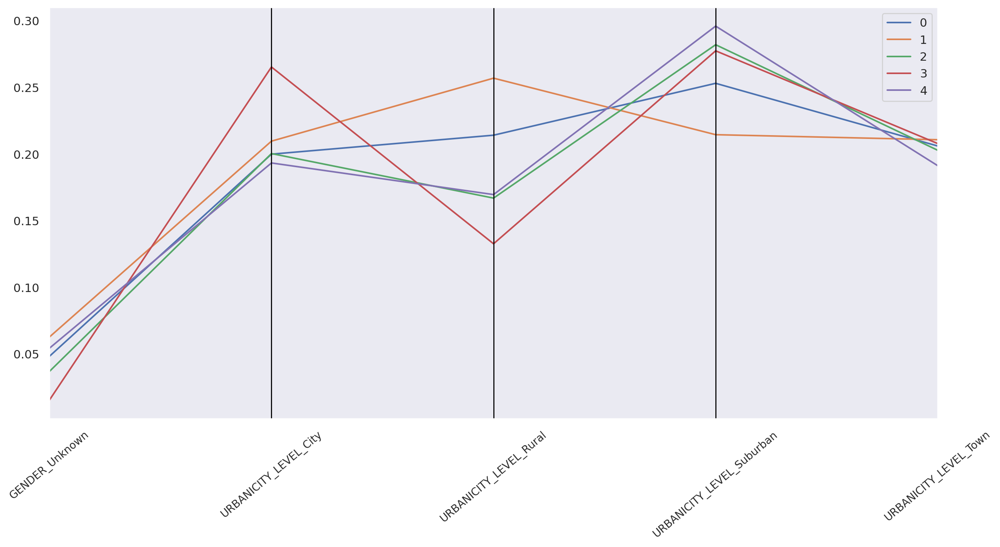

In [96]:
#plt.plot(hc_km_labeled_non_metric.iloc[:,61:66])
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_urbanicity, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

#### Interests

In [97]:
hc_km_interests = hc_km_labeled_non_metric.groupby('Labels_hc', as_index=False).mean().iloc[:,66:]
hc_km_interests['label'] = hc_km_interests.index
hc_km_interests

,URBANICITY_LEVEL_Urban,COLLECT1_Y,VETERANS_Y,BIBLE_Y,CATLG_Y,HOMEE_Y,PETS_Y,CDPLAY_Y,STEREO_Y,PCOWNERS_Y,PHOTO_Y,CRAFTS_Y,FISHER_Y,GARDENIN_Y,BOATS_Y,WALKER_Y,KIDSTUFF_Y,CARDS_Y,PLATES_Y,label
0,0.126954,0.057132,0.102324,0.093791,0.083662,0.009146,0.158763,0.134907,0.139311,0.115874,0.051430,0.088083,0.079094,0.139274,0.022659,0.107143,0.017642,0.011007,0.005826,0
1,0.108222,0.042309,0.109709,0.085233,0.069792,0.006433,0.120773,0.088294,0.104909,0.065668,0.037936,0.080443,0.062168,0.125322,0.012835,0.100392,0.011553,0.010417,0.004748,1
2,0.147965,0.056777,0.108426,0.096062,0.090635,0.013119,0.163769,0.161761,0.153119,0.144531,0.058948,0.090693,0.082021,0.150173,0.027797,0.117620,0.018624,0.010576,0.006577,2
3,0.116810,0.083158,0.185625,0.133111,0.123974,0.012782,0.193825,0.164523,0.185387,0.146093,0.079828,0.123625,0.103056,0.217062,0.025073,0.175635,0.023202,0.021534,0.010118,3
4,0.149975,0.038207,0.083560,0.067397,0.068748,0.009382,0.130058,0.120938,0.113105,0.112511,0.041651,0.057702,0.057519,0.110698,0.024175,0.079779,0.013968,0.006333,0.005277,4


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18]),
 [Text(0, 0, 'URBANICITY_LEVEL_Urban'),
  Text(1, 0, 'COLLECT1_Y'),
  Text(2, 0, 'VETERANS_Y'),
  Text(3, 0, 'BIBLE_Y'),
  Text(4, 0, 'CATLG_Y'),
  Text(5, 0, 'HOMEE_Y'),
  Text(6, 0, 'PETS_Y'),
  Text(7, 0, 'CDPLAY_Y'),
  Text(8, 0, 'STEREO_Y'),
  Text(9, 0, 'PCOWNERS_Y'),
  Text(10, 0, 'PHOTO_Y'),
  Text(11, 0, 'CRAFTS_Y'),
  Text(12, 0, 'FISHER_Y'),
  Text(13, 0, 'GARDENIN_Y'),
  Text(14, 0, 'BOATS_Y'),
  Text(15, 0, 'WALKER_Y'),
  Text(16, 0, 'KIDSTUFF_Y'),
  Text(17, 0, 'CARDS_Y'),
  Text(18, 0, 'PLATES_Y')])

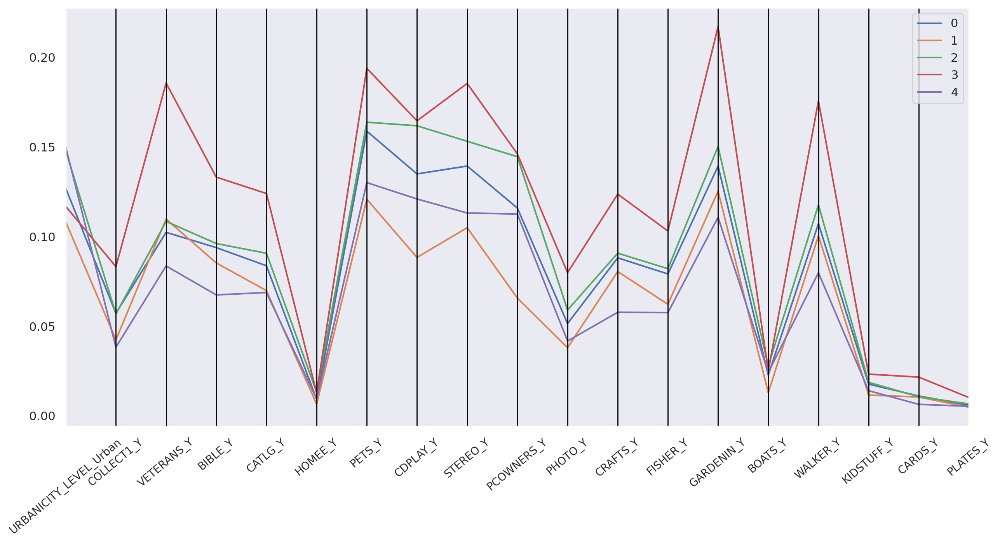

In [98]:
plt.figure(figsize=(15, 7))
pd.plotting.parallel_coordinates(hc_km_interests, class_column = 'label', color=sns.color_palette())
plt.xticks(fontsize=10, rotation=40)

## Visualization K-means on top of Hierarchical

In [99]:
km_hc_tsne = km_labeled_2.copy()

In [100]:
km_hc_tsne['Labels_km'] = km_hc_tsne['Labels_km'].map(dict(enumerate(hc_km_labels)))

In [101]:
km_hc_tsne.rename(columns={'Labels_km':'Labels_km_hc'}, inplace=True)

In [102]:
tsne_sample_hc = km_hc_tsne.sample(5000, random_state=42)
two_dim_km_hc = TSNE(random_state=42).fit_transform(tsne_sample_hc.drop(columns="Labels_km_hc"))

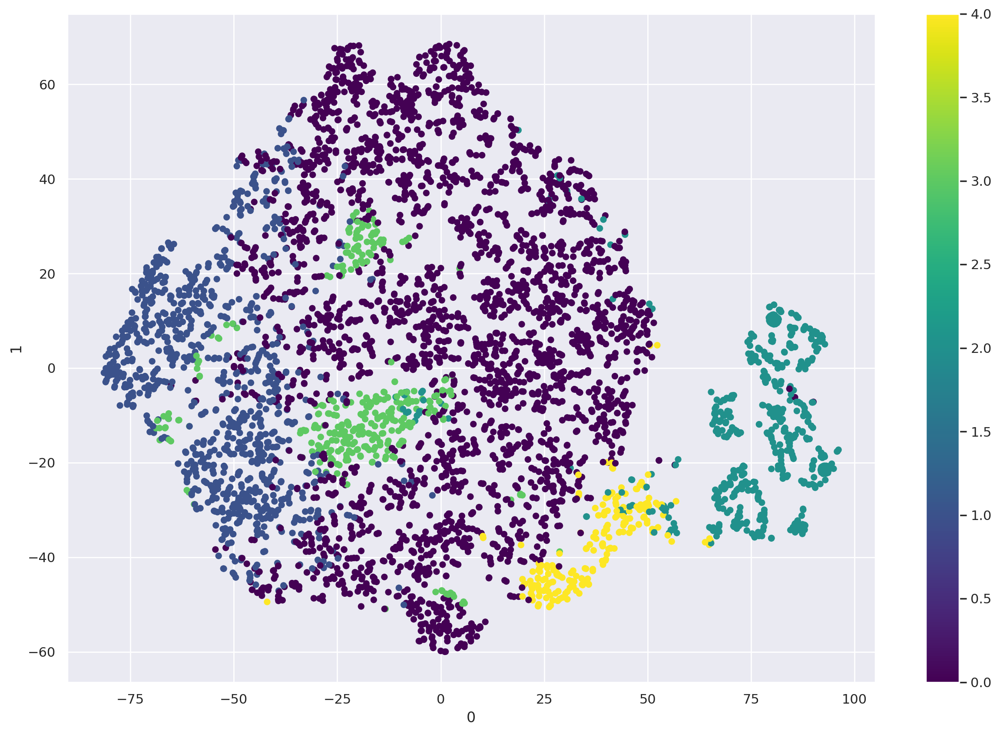

In [103]:
pd.DataFrame(two_dim_km_hc).plot.scatter(x=0, y=1, c=tsne_sample_hc['Labels_km_hc'], colormap='viridis', figsize=(15,10))
plt.show()

# Clustering by Perspectives

## K-means Clustering by Perspective

In [104]:
Demographic = pva_standard[['INCOME', 'LOG_AGE', 'LOG_AVGGIFT', 'LASTGIFT', 'MINRAMNT', 'LOG_RAMNTALL']]
Engagement =  pva_standard[['YEARS_FIRST_GIFT', 'NGIFTALL', 'GIFT_FREQUENCY', 'TIMELAG', 'HIT', 'CARDGIFT']]

In [105]:
Demographic_metric = pva_metric[['INCOME', 'LOG_AGE', 'LOG_AVGGIFT', 'LASTGIFT', 'MINRAMNT', 'LOG_RAMNTALL']]
Engagement_metric =  pva_metric[['YEARS_FIRST_GIFT', 'NGIFTALL', 'GIFT_FREQUENCY', 'TIMELAG', 'HIT', 'CARDGIFT']]

In [106]:
def get_ss(df):
    """Computes the sum of squares for all variables given a dataset
    """
    ss = np.sum(df.var() * (df.count() - 1))
    return ss  # return sum of sum of squares of each df variable

def r2(df, labels):
    sst = get_ss(df)
    ssw = np.sum(df.groupby(labels).apply(get_ss))
    return 1 - ssw/sst
    
def get_r2_scores(df, clusterer, min_k=2, max_k=10):
    """
    Loop over different values of k. To be used with sklearn clusterers.
    """
    r2_clust = {}
    for n in range(min_k, max_k):
        clust = clone(clusterer).set_params(n_clusters=n)
        labels = clust.fit_predict(df)
        r2_clust[n] = r2(df, labels)
    return r2_clust

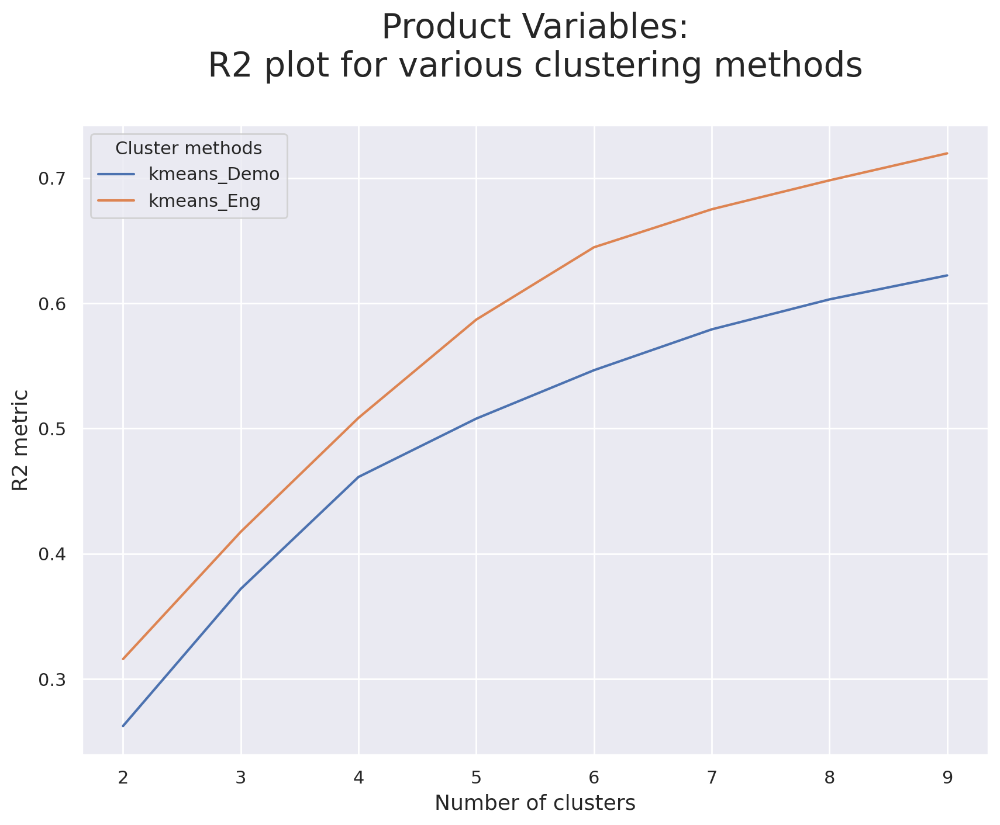

In [107]:
# Set up the clusterers
kmeans = KMeans(init='k-means++', n_init=15, random_state=42)


# Obtaining the R² scores for each cluster solution on product variables
r2_scores = {}
r2_scores['kmeans_Demo'] = get_r2_scores(Demographic, kmeans)
r2_scores['kmeans_Eng'] = get_r2_scores(Engagement, kmeans)


# Visualizing the R² scores for each cluster solution on product variables
pd.DataFrame(r2_scores).plot.line(figsize=(10,7))

 
plt.title("Product Variables:\nR2 plot for various clustering methods\n", fontsize=21)
plt.legend(title = 'Cluster methods', title_fontsize=11)
plt.xlabel('Number of clusters', fontsize=13)
plt.ylabel('R2 metric', fontsize=13)
plt.show()

In [108]:
kmeans_Demo = KMeans(n_clusters = 6, init = 'k-means++', n_init = 15, random_state=42)
Demo_labels = kmeans_Demo.fit_predict(Demographic)

kmeans_Eng = KMeans(n_clusters = 7, init = 'k-means++', n_init = 15, random_state = 42)
Eng_labels = kmeans_Eng.fit_predict(Engagement)

km_metric_perspective = pva_standard.copy()

km_metric_perspective['Demo_labels'] = Demo_labels
km_metric_perspective['Eng_labels'] = Eng_labels

In [109]:
km_metric_perspective.groupby(['Demo_labels', 'Eng_labels'])\
    .size()\
    .to_frame()\
    .reset_index()\
    .pivot('Demo_labels', 'Eng_labels', 0)

Eng_labels,0,1,2,3,4,5,6
Demo_labels,,,,,,,
0,1693.0,4081.0,3095.0,362.0,879.0,659.0,1822.0
1,5163.0,3587.0,2281.0,1899.0,1328.0,1754.0,1217.0
2,1.0,2214.0,148.0,NaN,413.0,571.0,10554.0
3,5740.0,6955.0,3358.0,1564.0,1941.0,2183.0,2450.0
4,3379.0,308.0,6363.0,4441.0,618.0,1044.0,177.0
5,2164.0,2357.0,683.0,500.0,900.0,669.0,607.0


## Merging Using Hierarchical Clustering

In [110]:
perspective_centroids = km_metric_perspective.groupby(['Demo_labels', 'Eng_labels']).mean()

In [111]:
linkage = 'ward'
hclust = AgglomerativeClustering(linkage = linkage, affinity='euclidean', distance_threshold = 0, n_clusters= None) # distance_threshold = 0
hclust_labels = hclust.fit_predict(perspective_centroids)

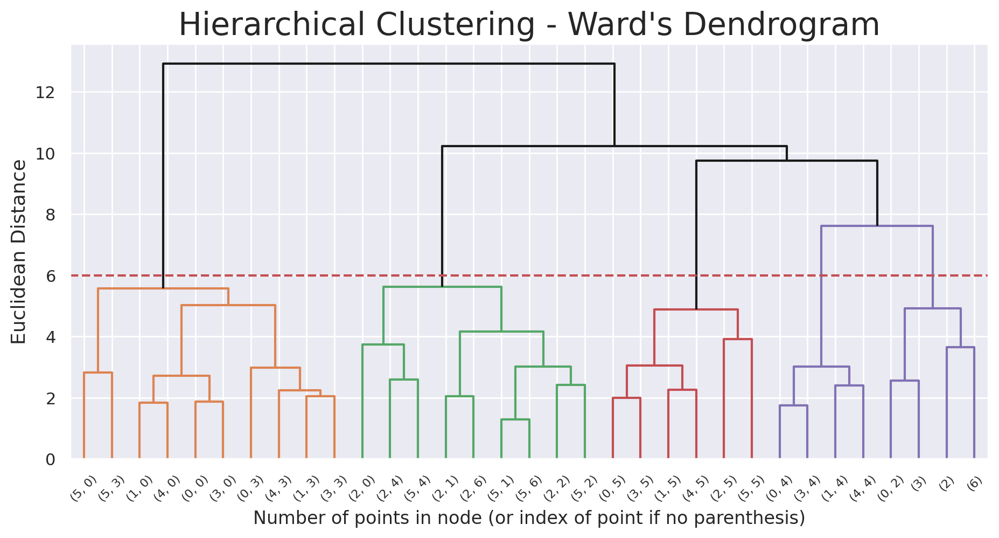

In [112]:
# Adapted from:
# https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html#sphx-glr-auto-examples-cluster-plot-agglomerative-dendrogram-py

# create the counts of samples under each node (number of points being merged)
counts = np.zeros(hclust.children_.shape[0])
n_samples = len(hclust.labels_)

# hclust.children_ contains the observation ids that are being merged together
# At the i-th iteration, children[i][0] and children[i][1] are merged to form node n_samples + i
for i, merge in enumerate(hclust.children_):
    # track the number of observations in the current cluster being formed
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            # If this is True, then we are merging an observation
            current_count += 1  # leaf node
        else:
            # Otherwise, we are merging a previously formed cluster
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

# the hclust.children_ is used to indicate the two points/clusters being merged (dendrogram's u-joins)
# the hclust.distances_ indicates the distance between the two points/clusters (height of the u-joins)
# the counts indicate the number of points being merged (dendrogram's x-axis)
linkage_matrix = np.column_stack(
    [hclust.children_, hclust.distances_, counts]
).astype(float)

 

# Plot the corresponding dendrogram
sns.set()
fig = plt.figure(figsize=(11,5))
# The Dendrogram parameters need to be tuned
y_threshold=6
dendrogram(linkage_matrix, truncate_mode='level', labels = perspective_centroids.index, p=5, above_threshold_color='k')
plt.hlines(y_threshold, 0, 1000, colors="r", linestyles="dashed")
plt.title(f'Hierarchical Clustering - {linkage.title()}\'s Dendrogram', fontsize=21)
plt.xlabel('Number of points in node (or index of point if no parenthesis)')
plt.ylabel(f'Euclidean Distance', fontsize=13)
plt.show()

In [113]:
# Re-running the Hierarchical clustering based on the correct number of clusters
hclust = AgglomerativeClustering(linkage='ward', affinity='euclidean', n_clusters = 5)
hclust_labels = hclust.fit_predict(perspective_centroids)
perspective_centroids['hclust_labels'] = hclust_labels

In [114]:
# Mapper between concatenated clusters and hierarchical clusters
cluster_mapper = perspective_centroids['hclust_labels'].to_dict()

#perspective_centroids_2 = perspective_centroids.copy()

# Mapping the hierarchical clusters on the centroids to the observations
km_metric_perspective['merged_labels'] = km_metric_perspective.apply(lambda row: cluster_mapper[(row['Demo_labels'], row['Eng_labels'])], axis=1)

# Merged cluster centroids
km_metric_perspective.groupby('merged_labels').mean()#[metric_features]

,INCOME,LASTGIFT,MINRAMNT,LOG_RAMNTALL,LOG_AGE,LOG_AVGGIFT,YEARS_FIRST_GIFT,NGIFTALL,GIFT_FREQUENCY,TIMELAG,HIT,CARDGIFT,Demo_labels,Eng_labels
merged_labels,,,,,,,,,,,,,,
0,0.149376,0.916442,1.556413,-0.749635,-0.211194,1.203338,-0.886409,-0.827587,-0.619763,-0.353361,-0.265203,-0.785938,2.763047,4.388376
1,-0.133688,-0.252527,-0.562232,0.912262,0.308476,-0.492371,1.108218,1.106607,0.079099,-0.121881,-0.163753,1.132175,2.734585,0.977439
2,0.019945,-0.262733,-0.285505,-0.356037,-0.197024,-0.220990,-0.507758,-0.398129,0.290624,-0.072736,-0.268979,-0.436144,2.038606,2.216647
3,0.031316,0.033557,-0.138862,0.159503,0.333835,0.002302,0.177053,-0.017687,-0.075288,0.027890,2.821449,-0.015826,2.465988,5.000000
4,-0.000182,-0.092718,-0.325418,0.098157,0.044434,-0.082389,0.615925,-0.135539,-0.189719,2.517963,-0.139287,-0.154084,2.019094,4.000000


## Characterizing Clusters by Perspective

In [115]:
km_hc_metric_perspective = pva_metric.copy()

km_hc_metric_perspective['Demo_labels'], km_hc_metric_perspective['Eng_labels'], km_hc_metric_perspective['merged_labels'] = km_metric_perspective['Demo_labels'],km_metric_perspective['Eng_labels'], km_metric_perspective['merged_labels'] 

In [116]:
def cluster_profiles(df, label_columns, figsize, compar_titles=None):
    """
    Pass df with labels columns of one or multiple clustering labels. 
    Then specify this label columns to perform the cluster profile according to them.
    """
    if compar_titles == None:
        compar_titles = [""]*len(label_columns)
        
    sns.set()
    fig, axes = plt.subplots(nrows=len(label_columns), ncols=2, figsize=figsize, squeeze=False)
    for ax, label, titl in zip(axes, label_columns, compar_titles):
        # Filtering df
        drop_cols = [i for i in label_columns if i!=label]
        dfax = df.drop(drop_cols, axis=1)
        
        # Getting the cluster centroids and counts
        centroids = dfax.groupby(by=label, as_index=False).mean()
        counts = dfax.groupby(by=label, as_index=False).count().iloc[:,[0,1]]
        counts.columns = [label, "counts"]
        
        # Setting Data
        pd.plotting.parallel_coordinates(centroids, label, color=sns.color_palette(), ax=ax[0])
        sns.barplot(x=label, y="counts", data=counts, ax=ax[1])

 

        #Setting Layout
        handles, _ = ax[0].get_legend_handles_labels()
        cluster_labels = ["Cluster {}".format(i) for i in range(len(handles))]
        ax[0].annotate(text=titl, xy=(0.95,1.1), xycoords='axes fraction', fontsize=13, fontweight = 'heavy') 
        ax[0].legend(handles, cluster_labels) # Adaptable to number of clusters
        ax[0].axhline(color="black", linestyle="--")
        ax[0].set_title("Cluster Means - {} Clusters".format(len(handles)), fontsize=13)
        ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=-20)
        ax[1].set_xticklabels(cluster_labels)
        ax[1].set_xlabel("")
        ax[1].set_ylabel("Absolute Frequency")
        ax[1].set_title("Cluster Sizes - {} Clusters".format(len(handles)), fontsize=13)
    
    plt.subplots_adjust(hspace=0.4, top=0.90)
    plt.suptitle("Cluster Simple Profilling", fontsize=23)
    plt.show()

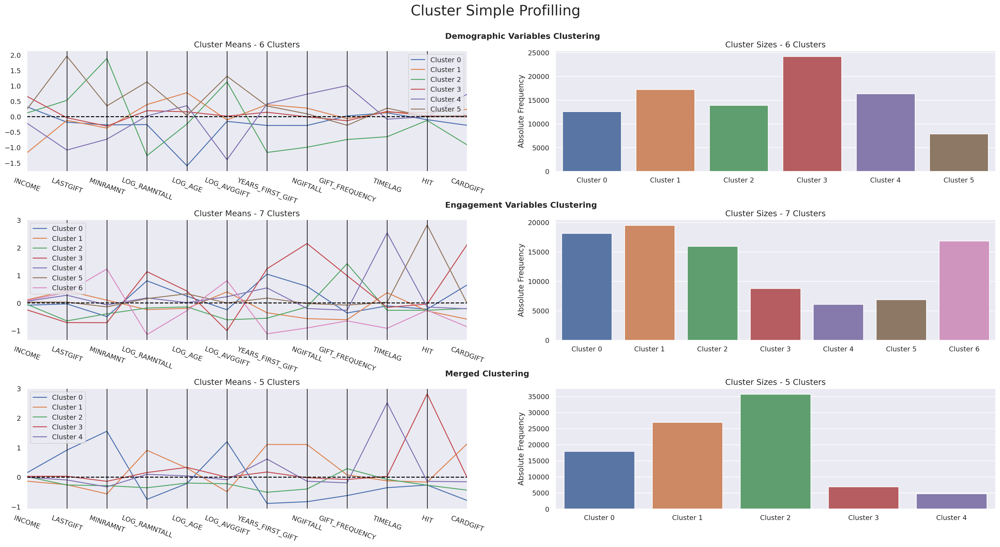

In [117]:
# Profilling each cluster (product, behavior, merged)
cluster_profiles(
    km_metric_perspective, 
    label_columns = ['Demo_labels', 'Eng_labels', 'merged_labels'],
    figsize = (28, 13),
    compar_titles = ["Demographic Variables Clustering", "Engagement Variables Clustering", "Merged Clustering"]
)

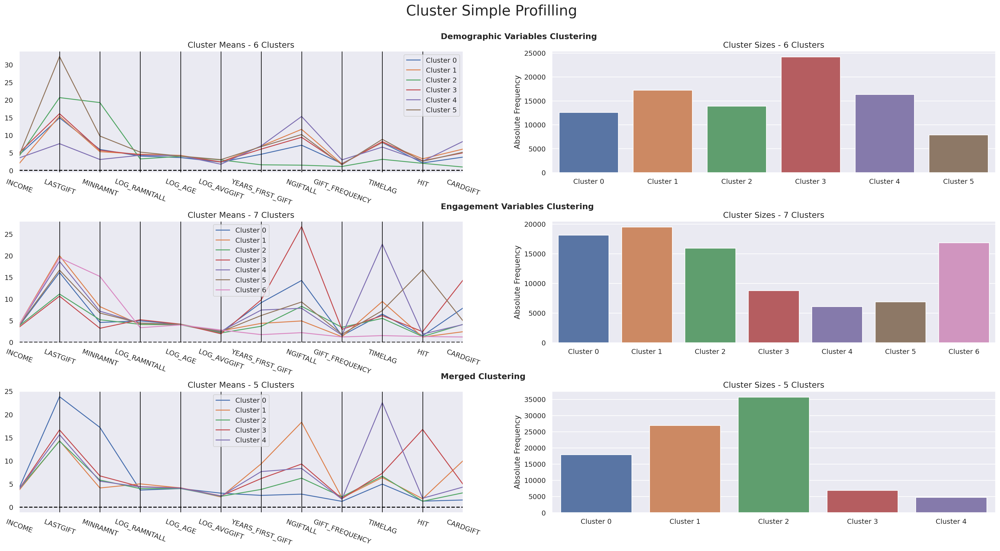

In [118]:
# Profilling each cluster (product, behavior, merged)
cluster_profiles(
    km_hc_metric_perspective, 
    label_columns = ['Demo_labels', 'Eng_labels', 'merged_labels'],
    figsize = (28, 13),
    compar_titles = ["Demographic Variables Clustering", "Engagement Variables Clustering", "Merged Clustering"]
)

## Cluster Visualization using TSNE

In [119]:
# This step can be quite time consuming: run it on a sample, on the features only.
tsne_sample_p = km_metric_perspective.sample(5000, random_state=42)
two_dim = TSNE(random_state=42).fit_transform(tsne_sample_p[pva_metric_list])

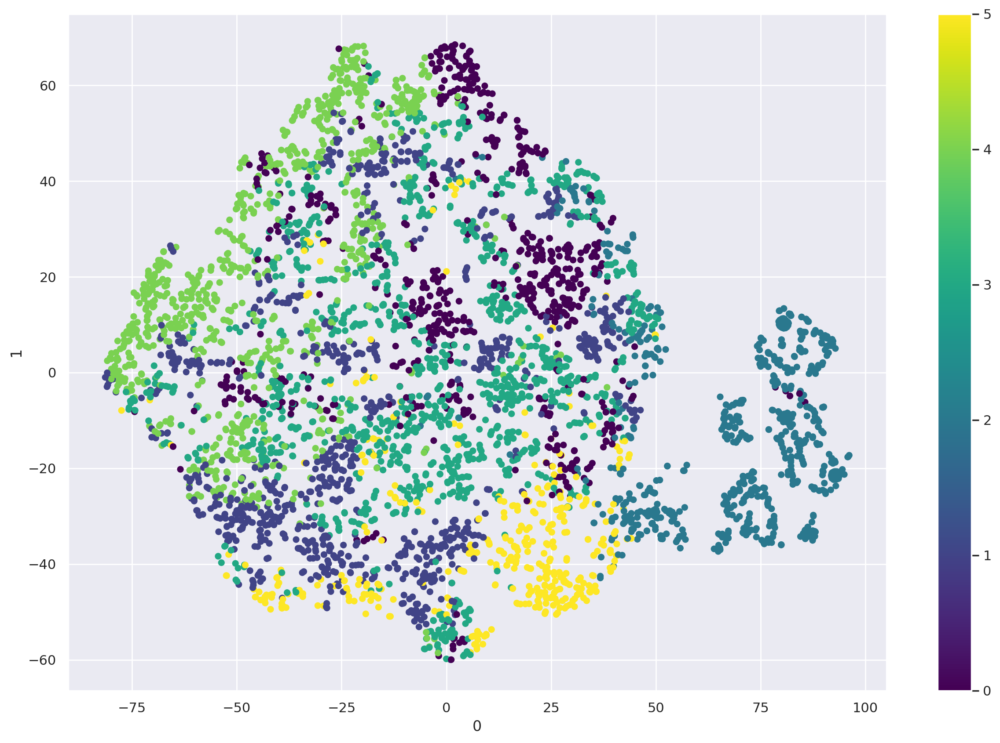

In [120]:
# # t-SNE visualization
pd.DataFrame(two_dim).plot.scatter(x=0, y=1, c = tsne_sample_p['Demo_labels'], colormap='viridis', figsize=(15,10))
plt.show()

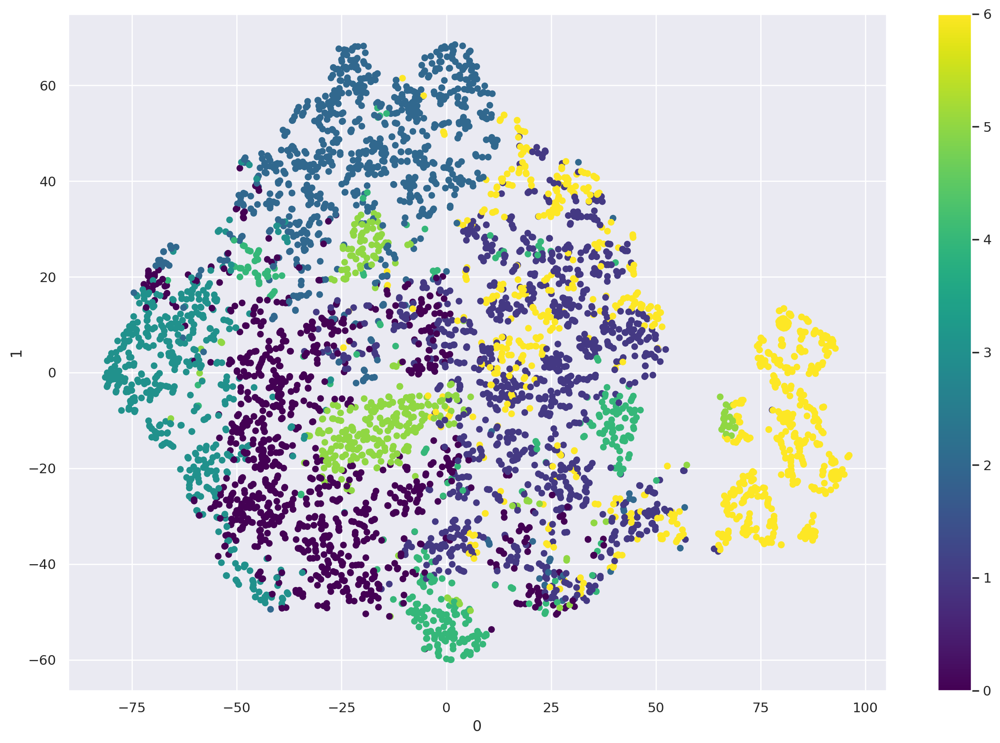

In [121]:
# # t-SNE visualization
pd.DataFrame(two_dim).plot.scatter(x=0, y=1, c = tsne_sample_p['Eng_labels'], colormap='viridis', figsize=(15,10))
plt.show()

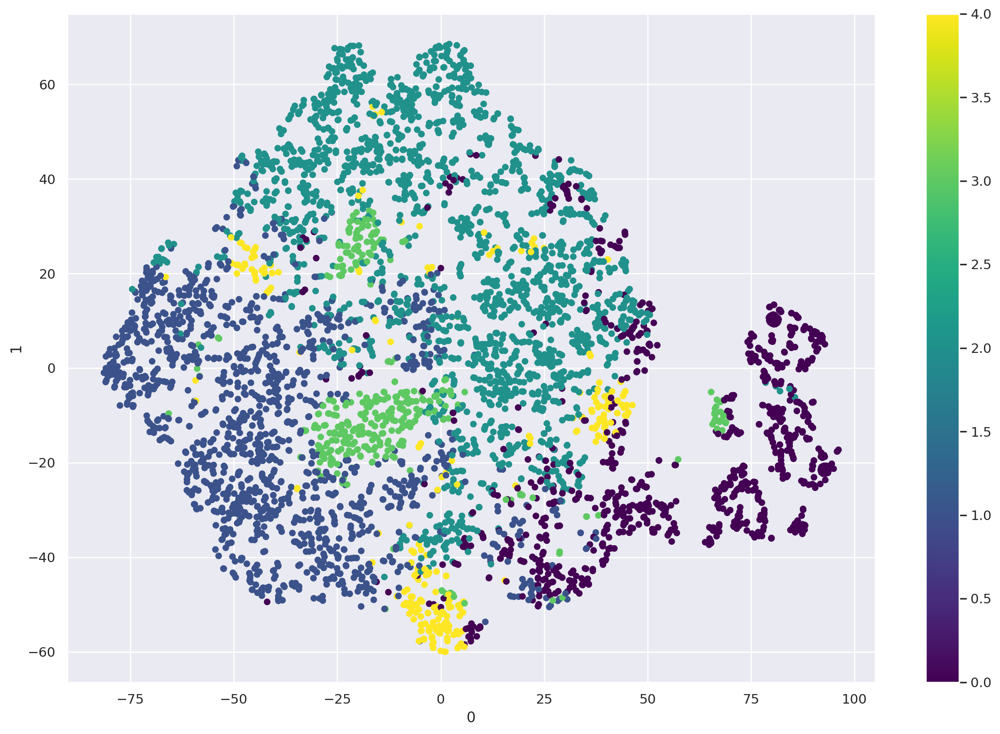

In [122]:
pd.DataFrame(two_dim).plot.scatter(x=0, y=1, c = tsne_sample_p['merged_labels'], colormap='viridis', figsize=(15,10))
plt.show()

## Conclusion

- **The data has real structure.** The Hopkins statistic is 0.12 (in `pyclustertend`'s convention, values near 0 indicate clustering and about 0.5 indicates random data), and 97% of donors survive the outlier filter.
- **Four K-means segments with clear marketing meaning** (cluster means on the original scale):
  - *Loyal veterans:* about 9.6 years since the first gift and 20 gifts, the highest lifetime giving, small average gifts, and the most responses to card mailings.
  - *New generous donors:* under 2 years and about 2 gifts, but the largest minimum and average gifts.
  - *Lapsing mid-tenure donors:* about 6 years and 7 gifts with the largest last gift, but the longest gap between the first and second gift.
  - *Frequent small givers:* the highest gift frequency and the smallest recent gifts.
- **The other two approaches agree on the main split** between long-tenure, high-count donors and recent, high-value donors; the perspective-based merge adds a small segment that responds to many mailings (high `HIT`) and one with long gaps between gifts (high `TIMELAG`).
- Demographics (income, age, state, interests) separate the segments far less than giving behaviour does.
